# Cluster sizes and phosphorylation in active droplets

1. Compute the time series of the largest-cluster size and of the number of pSer (`sim{ss}_size_cond_*.dat`)
2. Trajectories
3. Droplet size and phosphorylation vs number of enzymes (phase diagram)
4. Oscillations: cross-correlations and period
5. Limit cycles
6. CK1δ in the condensate

Size files have columns `time cond_size n_pSer` (+ `n_B`, added in `droplet_msm_rates.ipynb`).

# Setup

In [1]:
import os
import sys

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES   # data locations (set HPA_DATA_ROOT to use another copy)

from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
import scipy.signal as signal
from tqdm import tqdm
import gsd.hoomd

import hpa.cluster
from hpa.cluster import read_chains_in_condensate
from hpa.plots import plot_fading_trajectory
from hpa.stats import cross_correlation, sliding_window_correlation

plt.style.use('default')
plt.style.use(STYLES + 'rates_plot.mplstyle')

In [2]:
path_drop_fr = SIM + 'droplet_200-tdp43-lcd/'
path_drop_fr_an = AN + 'droplet_200-tdp43-lcd/'
path_drop_fr_pl = PL + 'droplet_200-tdp43-lcd/'
path_pser = SIM + 'fixed_pser_random_droplets/'
path_pser_an = AN + 'fixed_pser_random_droplets/'

N_CHAINS = 200       # TDP-43 LCD chains
CHAIN_LENGTH = 154
THRESHOLD = 8        # chains with >= THRESHOLD pSer are B, the others A
DT_SNAP = 200000     # MD steps between dump frames
SIMS = [1, 2, 3]


def drop_name(sim_type, n_k, n_p):
    return f'sim_{sim_type}_{N_CHAINS}-tdp43-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01'


def sim_prefix(sim_type, n_k, n_p, ss):
    '''Prefix of the simulation files, e.g. + '_fr01_dump.gsd'.'''
    return (f'{path_drop_fr}{drop_name(sim_type, n_k, n_p)}/'
            f'sim{ss}_{sim_type}_{N_CHAINS}-tdp43-lcd_{n_k}-com-ck1d-open_{n_p}-com-pp3_CAL3')


def an_dir(sim_type, n_k, n_p):
    return f'{path_drop_fr_an}{drop_name(sim_type, n_k, n_p)}/'


def timelines_file(sim_type, n_k, n_p, ss, six_states=False):
    tag = '_6states' if six_states else ''
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_timelines{tag}_treshold{THRESHOLD}.json'


def size_cond_file(sim_type, n_k, n_p, ss):
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_size_cond_{drop_name(sim_type, n_k, n_p)[4:]}.dat'


def savefig(prefix, dpi=1200):
    for ext in ('pdf', 'png'):
        plt.savefig(f'{prefix}.{ext}', dpi=dpi)

N_PART = N_CHAINS * CHAIN_LENGTH
NPSER_EQ = [5, 6, 7, 8, 8.5, 9]   # pSer per chain of the equilibrium droplets (no reactions)


def size_cond_timeseries(dirpath, file_suffix, sim, segments, stride=20):
    '''Largest-cluster size (chains) and number of pSer every `stride` frames.

    segments: [(dump name, n_frames), ...] consecutive dump files; frame numbers continue across them.
    Returns times [MD steps], cluster size, n_pSer.
    '''
    times, sizes, npser = [], [], []
    offset = 0
    for dump, n_frames in segments:
        frames = np.arange(0, n_frames, stride)
        cs, n_p = hpa.cluster.chains_in_condensate(dirpath, file_suffix + dump, n_sims=[sim], times=frames,
                                                   n_particles=N_PART, n_clusters=1)
        times.append(frames + offset)
        sizes.append(cs.flatten())
        npser.append(n_p)
        offset += n_frames
    return np.concatenate(times) * DT_SNAP, np.concatenate(sizes), np.concatenate(npser)


def load_size_cond(n_k, n_p, therm_frames=0, sim_type='ness', sims=SIMS):
    '''Rows (time, cond_size, n_pSer) of all replicas after therm_frames dump frames.'''
    data = [np.loadtxt(size_cond_file(sim_type, n_k, n_p, ss), usecols=(0, 1, 2)) for ss in sims]
    return np.concatenate([d[d[:, 0] > therm_frames * DT_SNAP] for d in data])

# 1. Cluster size time series
## NESS droplets

In [58]:
sim_type, n_k, n_p = 'ness', 3, 15
dirpath = path_drop_fr + drop_name(sim_type, n_k, n_p) + '/'
file_suffix = f'{sim_type}_200-tdp43-lcd_{n_k}-com-ck1d-open_{n_p}-com-pp3_CAL3_fr01_'

# dump files of every replica and their number of frames
SEGMENTS = {1: [('dump.gsd', 10000), ('20us_dump.gsd', 10000)],
            2: [('dump.gsd', 10000)],  # , ('20us_dump.gsd', 10000), ('40us_dump.gsd', 10000)],
            3: [('dump.gsd', 10000), ('20us_dump.gsd', 10000)]
           }

for ss, segments in SEGMENTS.items():
    times, cond_size, n_pser = size_cond_timeseries(dirpath, file_suffix, ss, segments)
    np.savetxt(size_cond_file(sim_type, n_k, n_p, ss), np.column_stack([times, cond_size, n_pser]), header='cond_size n_pser')

/localscratch/zippoema/lib/python_envs/hpa_env/lib/python3.11/site-packages/gsd/hoomd.py:1125: FutureWarning: The 'rb' mode is deprecated, use 'r'
  gsdfileobj = fl.open(name=str(name),


10000 1


100%|█████████████████████████████████████████████████████████████████| 500/500 [00:12<00:00, 40.61it/s]


10000 1


100%|█████████████████████████████████████████████████████████████████| 500/500 [00:12<00:00, 40.75it/s]


10000 1


100%|█████████████████████████████████████████████████████████████████| 500/500 [00:11<00:00, 42.77it/s]


10000 1


100%|████████████████████████████████████████████████████████████████| 500/500 [00:04<00:00, 121.89it/s]


10000 1


100%|████████████████████████████████████████████████████████████████| 500/500 [00:02<00:00, 204.19it/s]


## Equilibrium droplets (fixed pSer, no reactions)

In [7]:
for npser in NPSER_EQ:
    dirpath = path_pser + f'sim_eq_200-tdp43-lcd-{npser}pser_fr01/'
    file_suffix = f'eq_200-tdp43-lcd-{npser}pser_CAL3_fr01_'
    for ss in SIMS:
        times, cond_size, n_pser = size_cond_timeseries(dirpath, file_suffix, ss, [('dump.gsd', 2500)])
        np.savetxt(path_pser_an + f'sim{ss}_size_cond_eq_200-tdp43-lcd-{npser}pser_CAL3_fr01.dat',
                   np.column_stack([times, cond_size, n_pser]), header='cond_size n_pser')

2500 1


100%|█████████████████████████████████████████████████████████████████████████████████| 125/125 [00:02<00:00, 53.23it/s]


2500 1


100%|█████████████████████████████████████████████████████████████████████████████████| 125/125 [00:02<00:00, 51.26it/s]


2500 1


100%|█████████████████████████████████████████████████████████████████████████████████| 125/125 [00:02<00:00, 55.59it/s]


... (26 outputs left out)

2500 1


100%|█████████████████████████████████████████████████████████████████████████████████| 125/125 [00:02<00:00, 53.85it/s]


2500 1


100%|█████████████████████████████████████████████████████████████████████████████████| 125/125 [00:02<00:00, 56.66it/s]


# 2. Trajectories

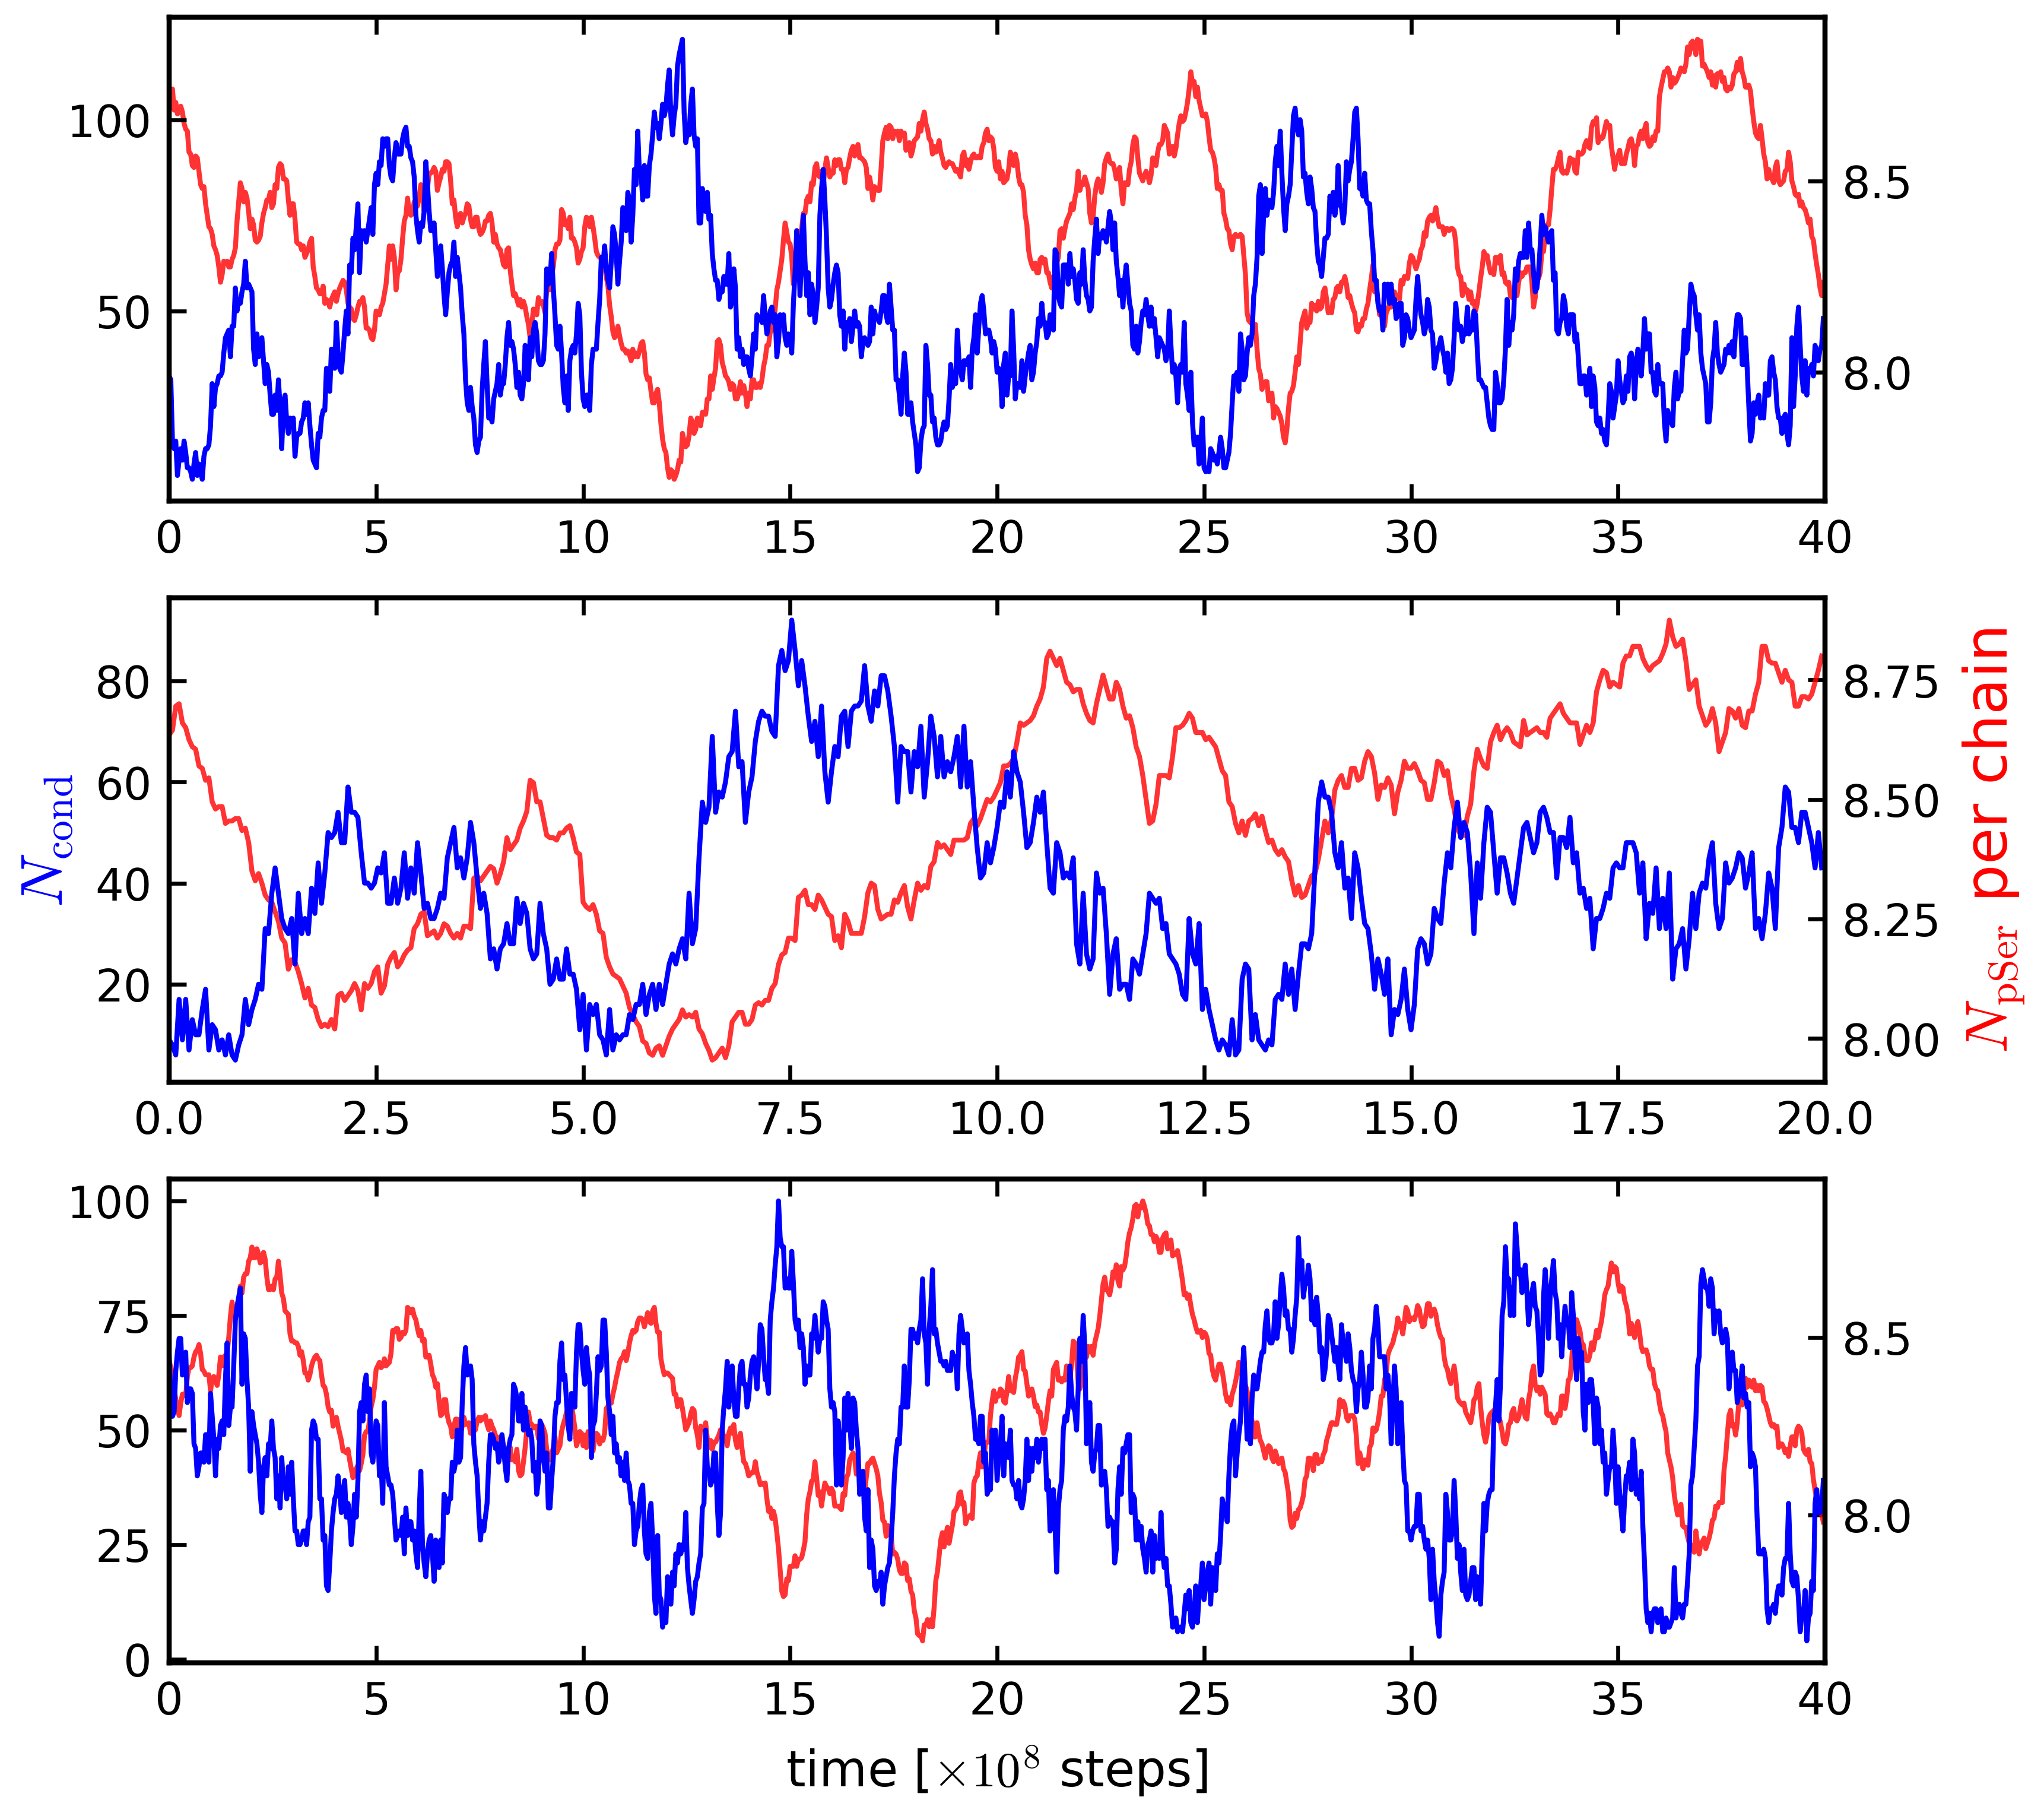

In [59]:
def plot_size_and_npser(ax, t, cs, n_p):
    '''Cluster size (left axis, blue) and pSer per chain (right axis, red) vs time in 1e8 steps.'''
    ax.plot(t / 1e8, cs, 'b')
    axr = ax.twinx()
    axr.set_zorder(ax.get_zorder() - 1)
    axr.plot(t / 1e8, n_p / N_CHAINS, 'r', alpha=0.8)
    axr.patch.set_visible(False)
    ax.patch.set_visible(False)
    return axr


sim_type, n_k, n_p = 'ness', 3, 15
runs = {ss: read_chains_in_condensate(path_drop_fr_an, 200, n_k, n_p, sim_type, n_sim=ss) for ss in SIMS}
t_ends = {1: 40, 2: 20, 3: 40}

fig, axes = plt.subplots(3, 1, figsize=(6, 6))
for ax, ss in zip(axes, SIMS):
    axr = plot_size_and_npser(ax, *runs[ss])
    ax.set_xlim(0, t_ends[ss])
    if ss == 2:
        ax.set_ylabel(r'$N_{\mathrm{cond}}$', color='b', fontsize=12)
        axr.set_ylabel(r'$N_{\mathrm{pSer}}$ per chain', color='r', fontsize=12)
axes[-1].set_xlabel(r'time [$\times 10^8$ steps]')
savefig(path_drop_fr_pl + f'{drop_name(sim_type, n_k, n_p)}/cluster_size_200-tdp-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01', dpi=600)

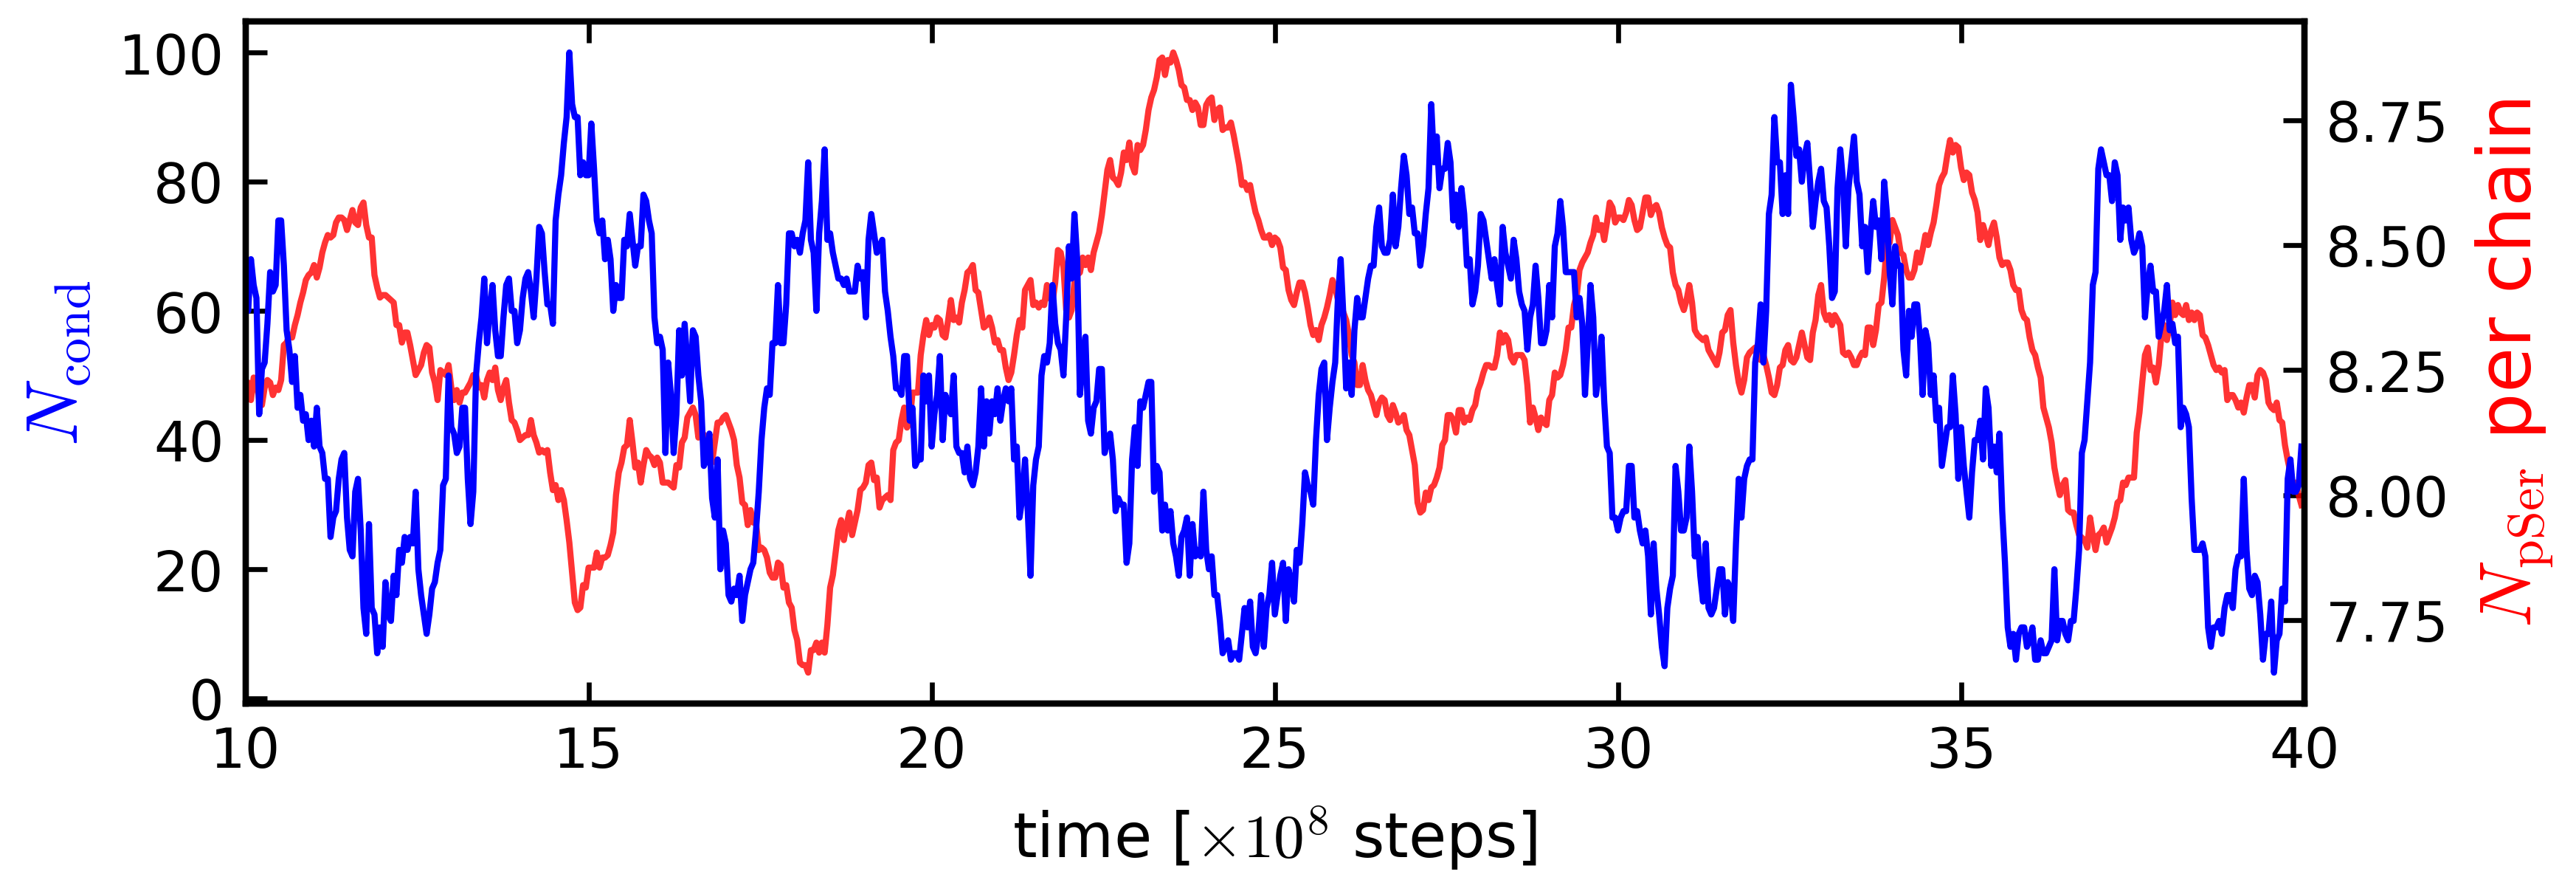

In [60]:
nsim = 3
fig, ax1 = plt.subplots(1, 1, figsize=(6, 2))
axr = plot_size_and_npser(ax1, *runs[nsim])
ax1.set_ylabel(r'$N_{\mathrm{cond}}$', color='b', fontsize=12)
axr.set_ylabel(r'$N_{\mathrm{pSer}}$ per chain', color='r', fontsize=12)
ax1.set_xlabel(r'time [$\times 10^8$ steps]')
ax1.set_xlim(10, t_ends[nsim])
savefig(path_drop_fr_pl + f'{drop_name(sim_type, n_k, n_p)}/sim{nsim}_cluster_size_200-tdp-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01', dpi=600)

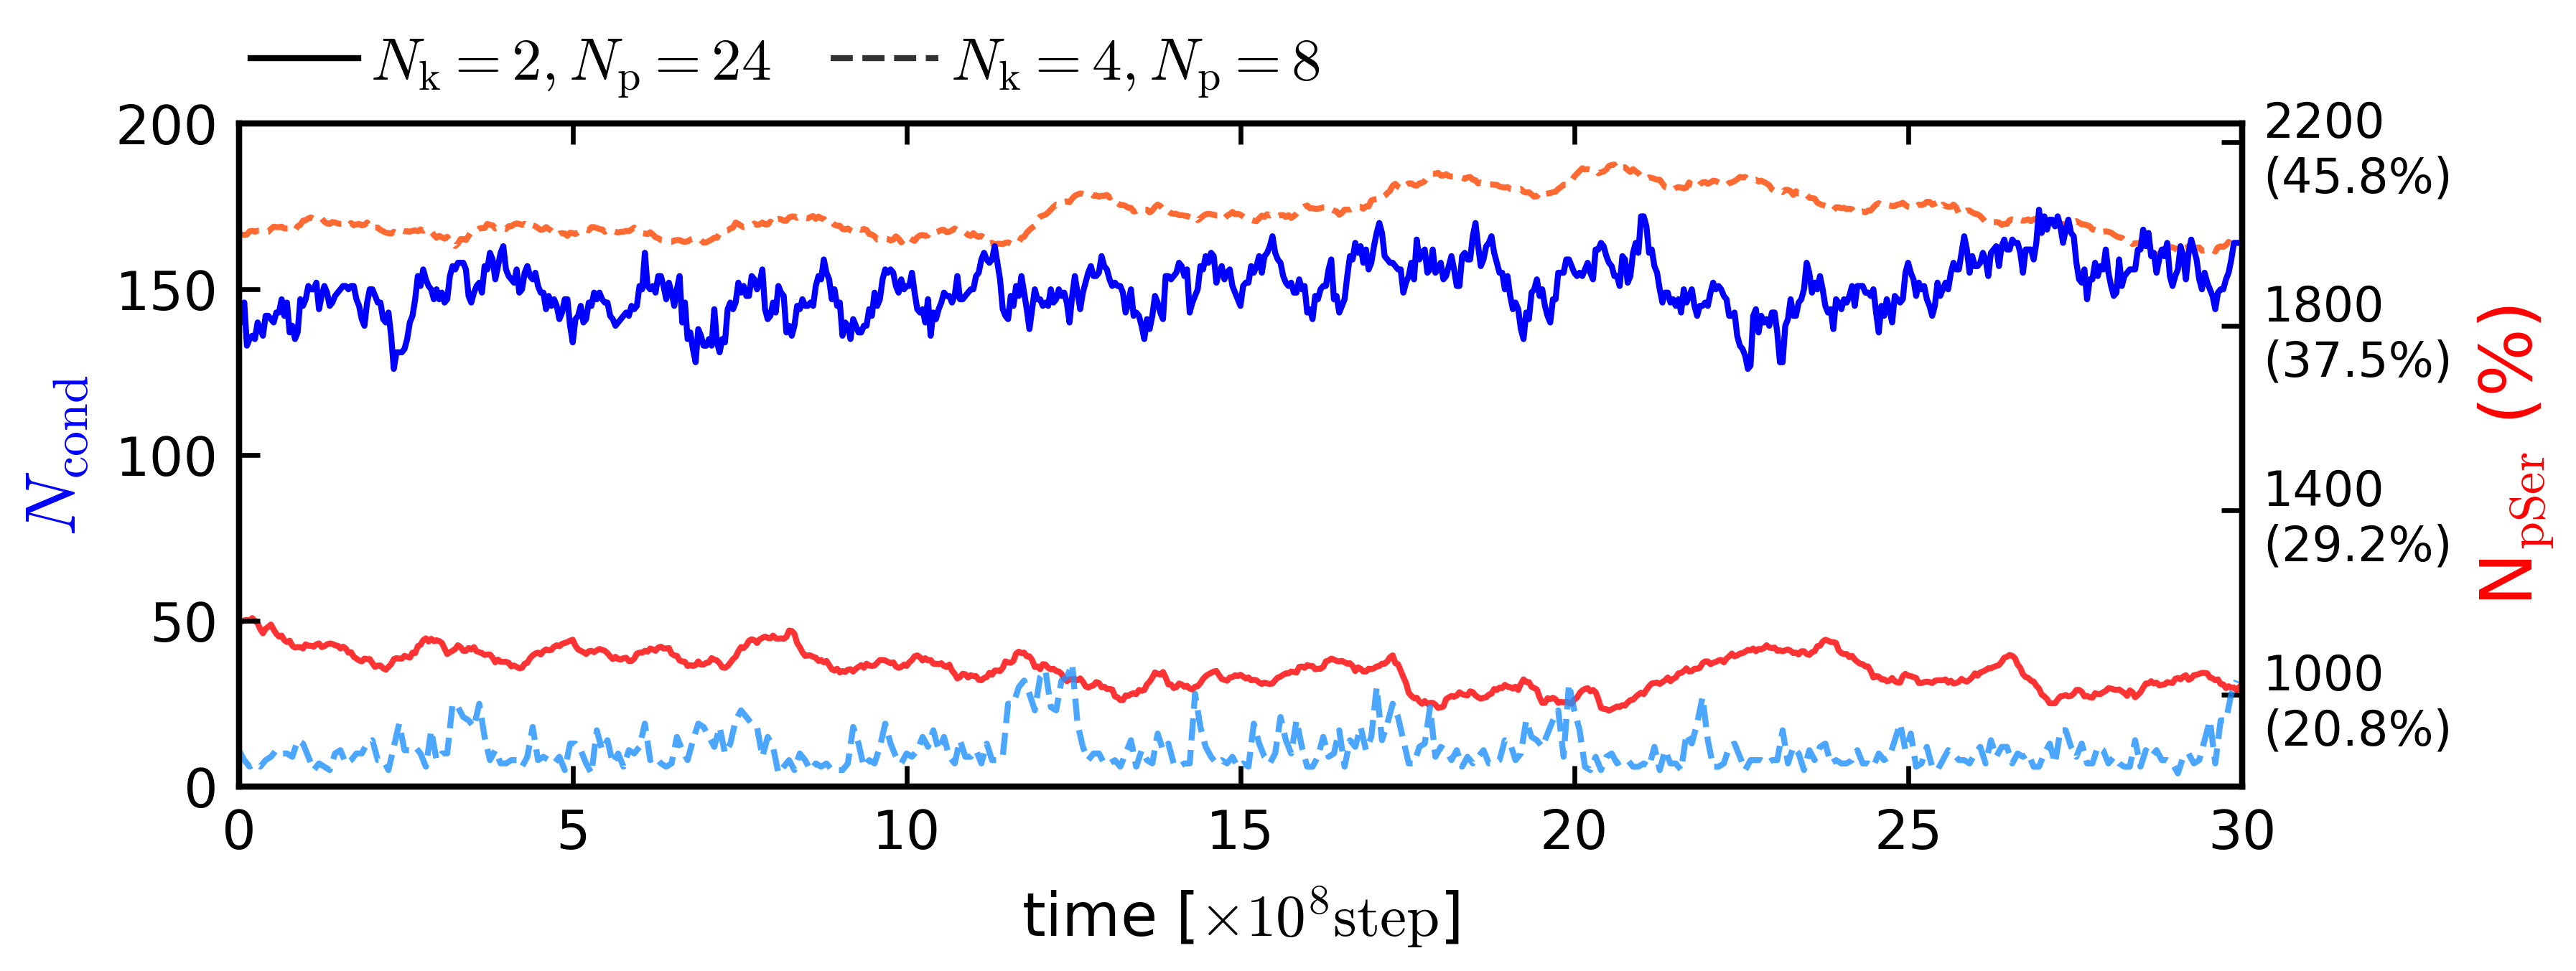

In [26]:
t_24, cond_size_24, np_24 = read_chains_in_condensate(path_drop_fr_an, 200, 2, 24, 'ness', n_sim=1)
t_4_8, cond_size_4_8, np_4_8 = read_chains_in_condensate(path_drop_fr_an, 200, 4, 8, 'ness', n_sim=1)

fig, ax1 = plt.subplots(1, 1, figsize=(6, 2))
ax11 = ax1.twinx()
ax11.set_zorder(ax1.get_zorder() - 1)
ax1.plot(t_24 / 1e8, cond_size_24, 'b')
ax1.plot(t_4_8[::2] / 1e8, cond_size_4_8[::2], '--', alpha=0.8, c='dodgerblue')
ax11.plot(t_24 / 1e8, np_24, 'r', alpha=0.8, label=r'$N_\mathrm{k}=2, N_\mathrm{p}=24$')
ax11.plot(t_4_8 / 1e8, np_4_8, '--', c='orangered', alpha=0.8, label=r'$N_\mathrm{k}=4, N_\mathrm{p}=8$')

ax1.set_ylabel(r'$N_{\mathrm{cond}}$', fontsize=12, color='b')
ax1.set_xlabel(r'time [$\times 10^8 \mathrm{step}$]')
ax11.set_ylabel(r'N$_{\mathrm{pSer}}$ (%)', fontsize=12, color='r')
ax1.patch.set_visible(False)
ax11.patch.set_visible(False)
ax1.set_xlim(0, 30)
ax11.set_xlim(0, 30)
ax1.set_ylim(0, 200)
ax11.set_ylim(4.0 * 200, 11.2 * 200)
ax1.plot([], [], '-k', label=r'$N_\mathrm{k}=2, N_\mathrm{p}=24$')
ax1.plot([], [], '--k', alpha=0.8, label=r'$N_\mathrm{k}=4, N_\mathrm{p}=8$')
ax1.legend(ncols=2, frameon=False, loc=(0, 1.02), fontsize=10)

ax11.set_yticks([1000,1400,1800,2200],['1000\n(20.8%)','1400\n(29.2%)','1800\n(37.5%)','2200\n(45.8%)'], fontsize=8)

savefig(path_drop_fr_pl + 'cluster_size_and_npser_200-tdp-lcd_fr01', dpi=600)

# 3. Droplet size vs number of enzymes

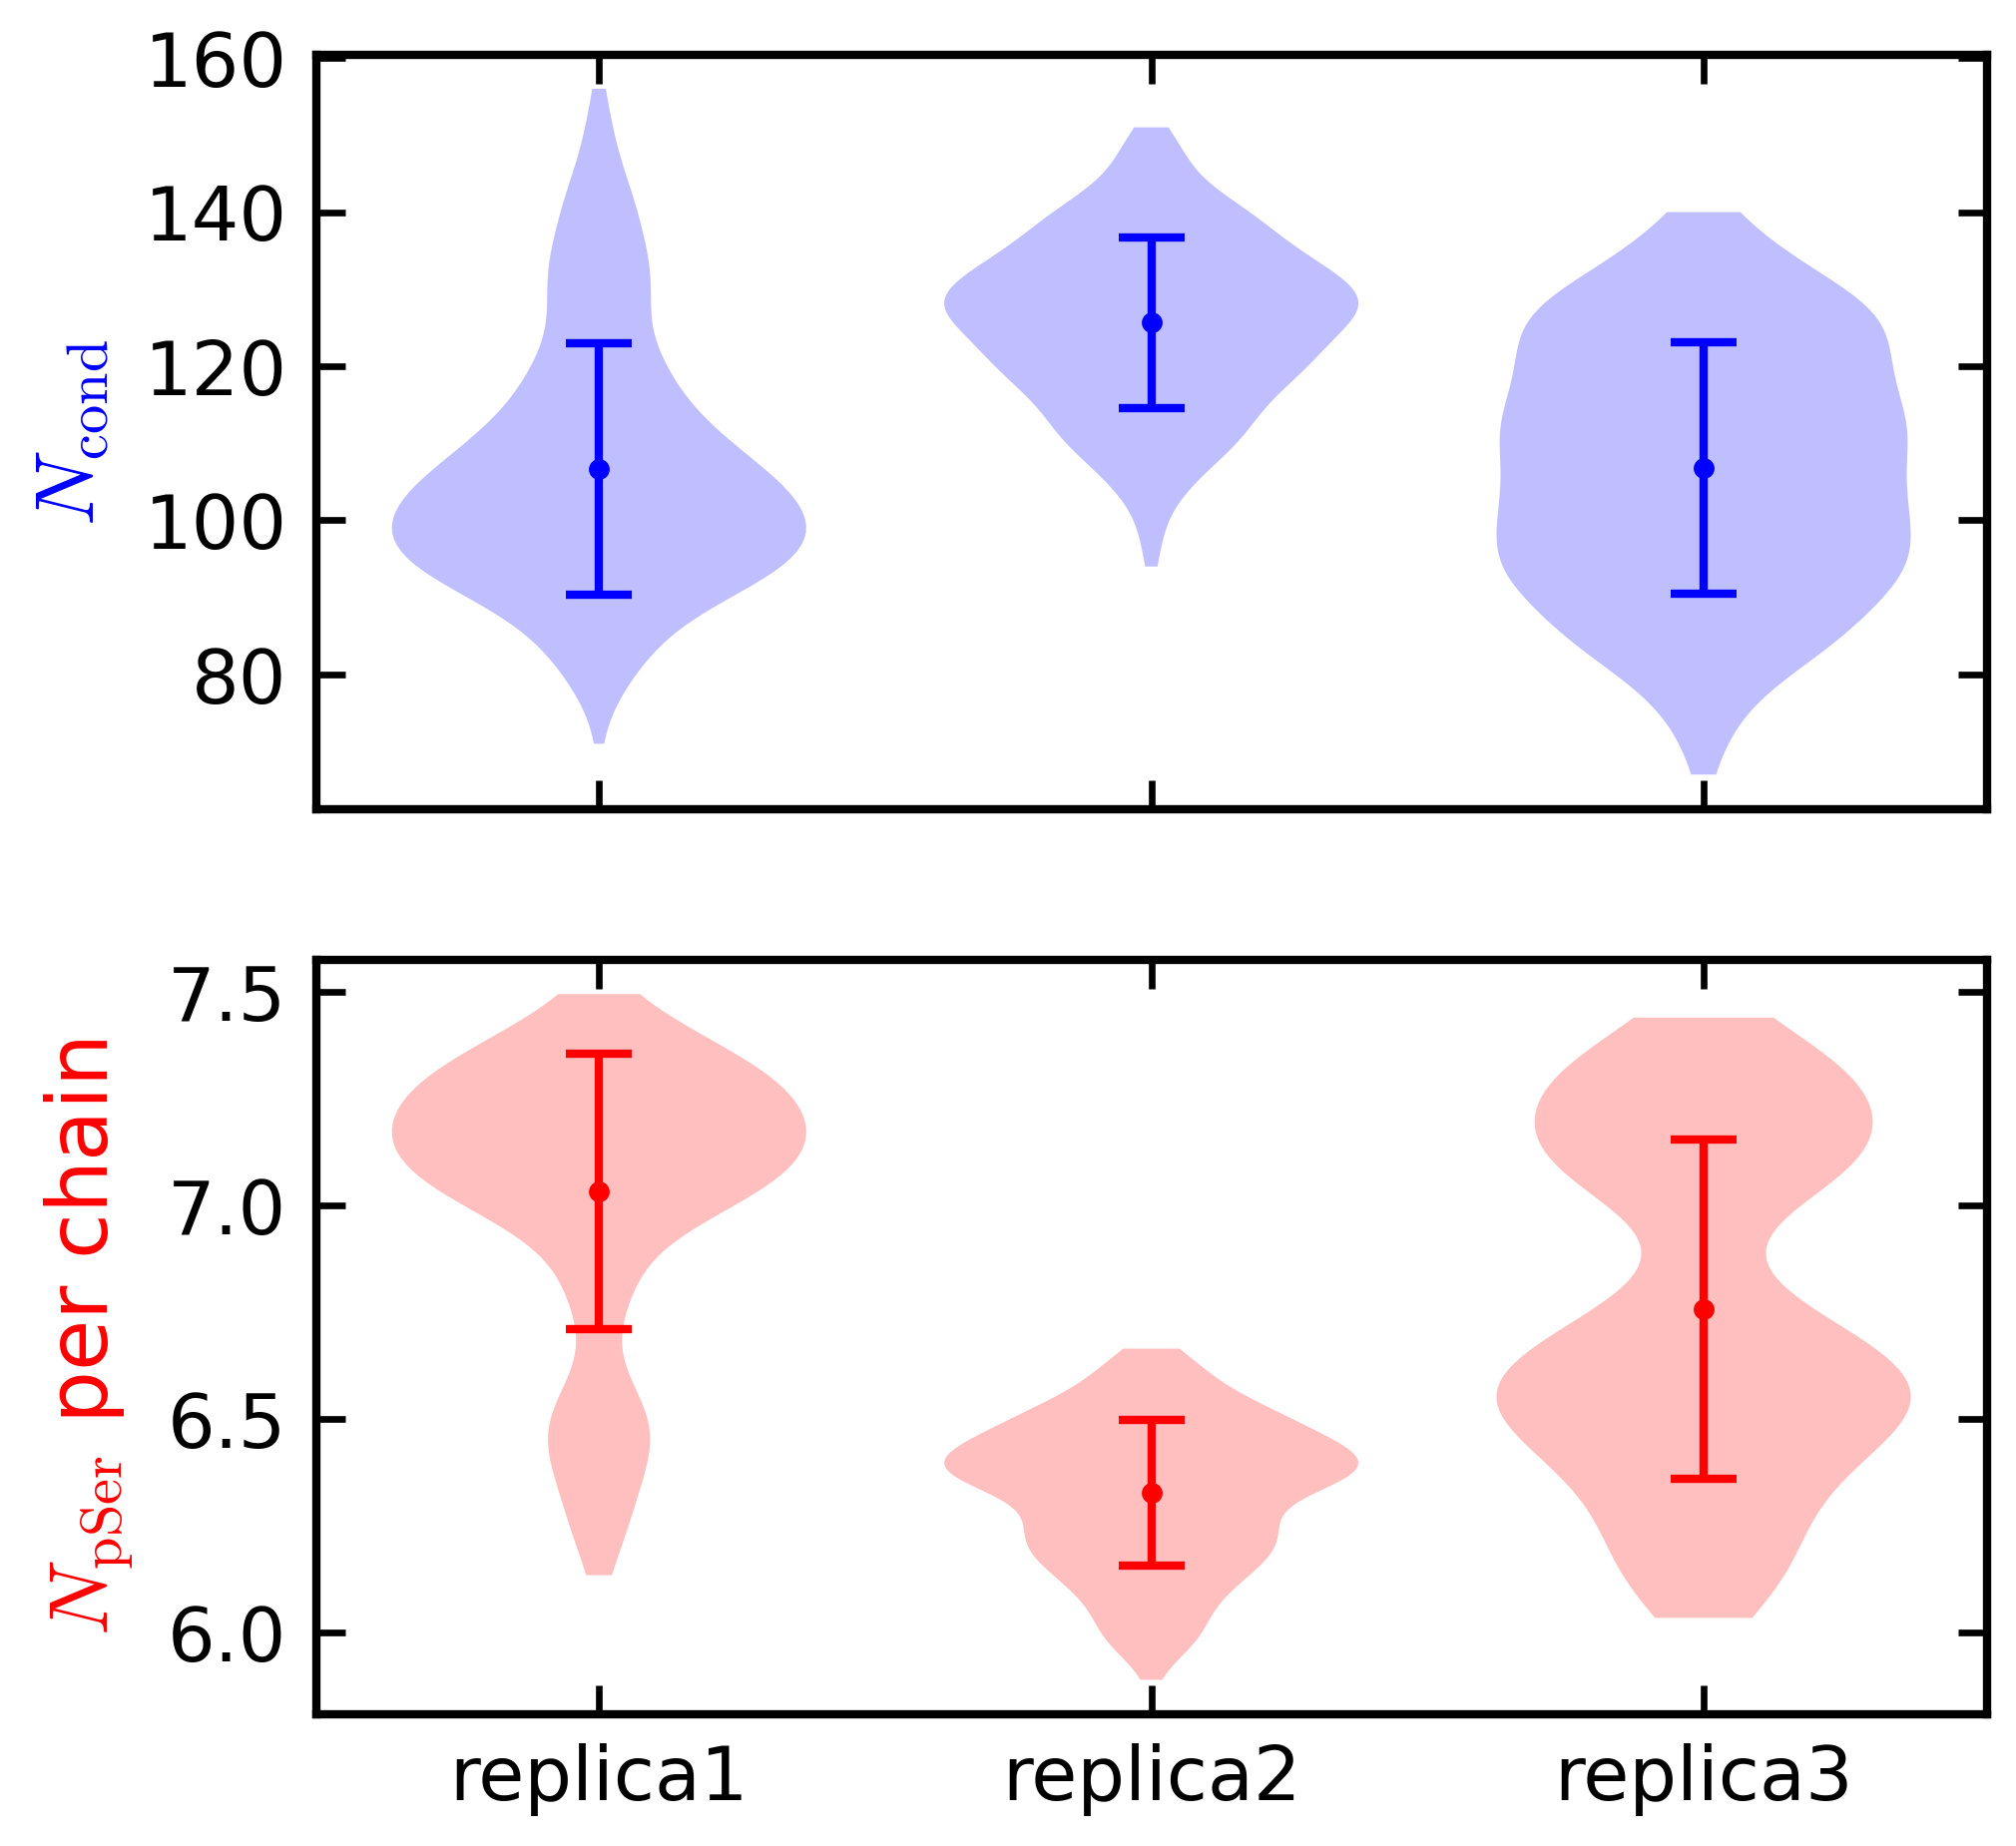

In [35]:
def violins(ax, data, positions, color):
    parts = ax.violinplot(data, positions=positions, widths=0.75, showmeans=False, showmedians=False, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_alpha(0.25)


n_k, n_p = 2, 16
cs_l, np_l = [], []
for ss in SIMS:
    data = np.loadtxt(size_cond_file('ness', n_k, n_p, ss), usecols=(0, 1, 2))
    data = data[data[:, 0] > 0]
    cs_l.append(data[:, 1])
    np_l.append(data[:, 2] / N_CHAINS)

fig, (ax1, ax11) = plt.subplots(2, 1, figsize=(3.6, 3.6), sharex=True)
violins(ax1, cs_l, SIMS, 'blue')
violins(ax11, np_l, SIMS, 'red')
ax1.errorbar(SIMS, [np.mean(x) for x in cs_l], [np.std(x) for x in cs_l], fmt='.', capsize=4, color='b')
ax11.errorbar(SIMS, [np.mean(x) for x in np_l], [np.std(x) for x in np_l], fmt='.', capsize=4, color='r')
ax1.set_ylabel(r'$N_{\mathrm{cond}}$', color='b')
ax11.set_ylabel(r'$N_{\mathrm{pSer}}$ per chain', color='r')
ax1.set_xticks(SIMS, [f'replica{ss}' for ss in SIMS], rotation=45)
savefig(path_drop_fr_pl + f'{drop_name("ness", n_k, n_p)}/drop_cond_size_nPP3_200-tdp43-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01', dpi=600)

## Size and phosphorylation vs N_p (N_k = 2)

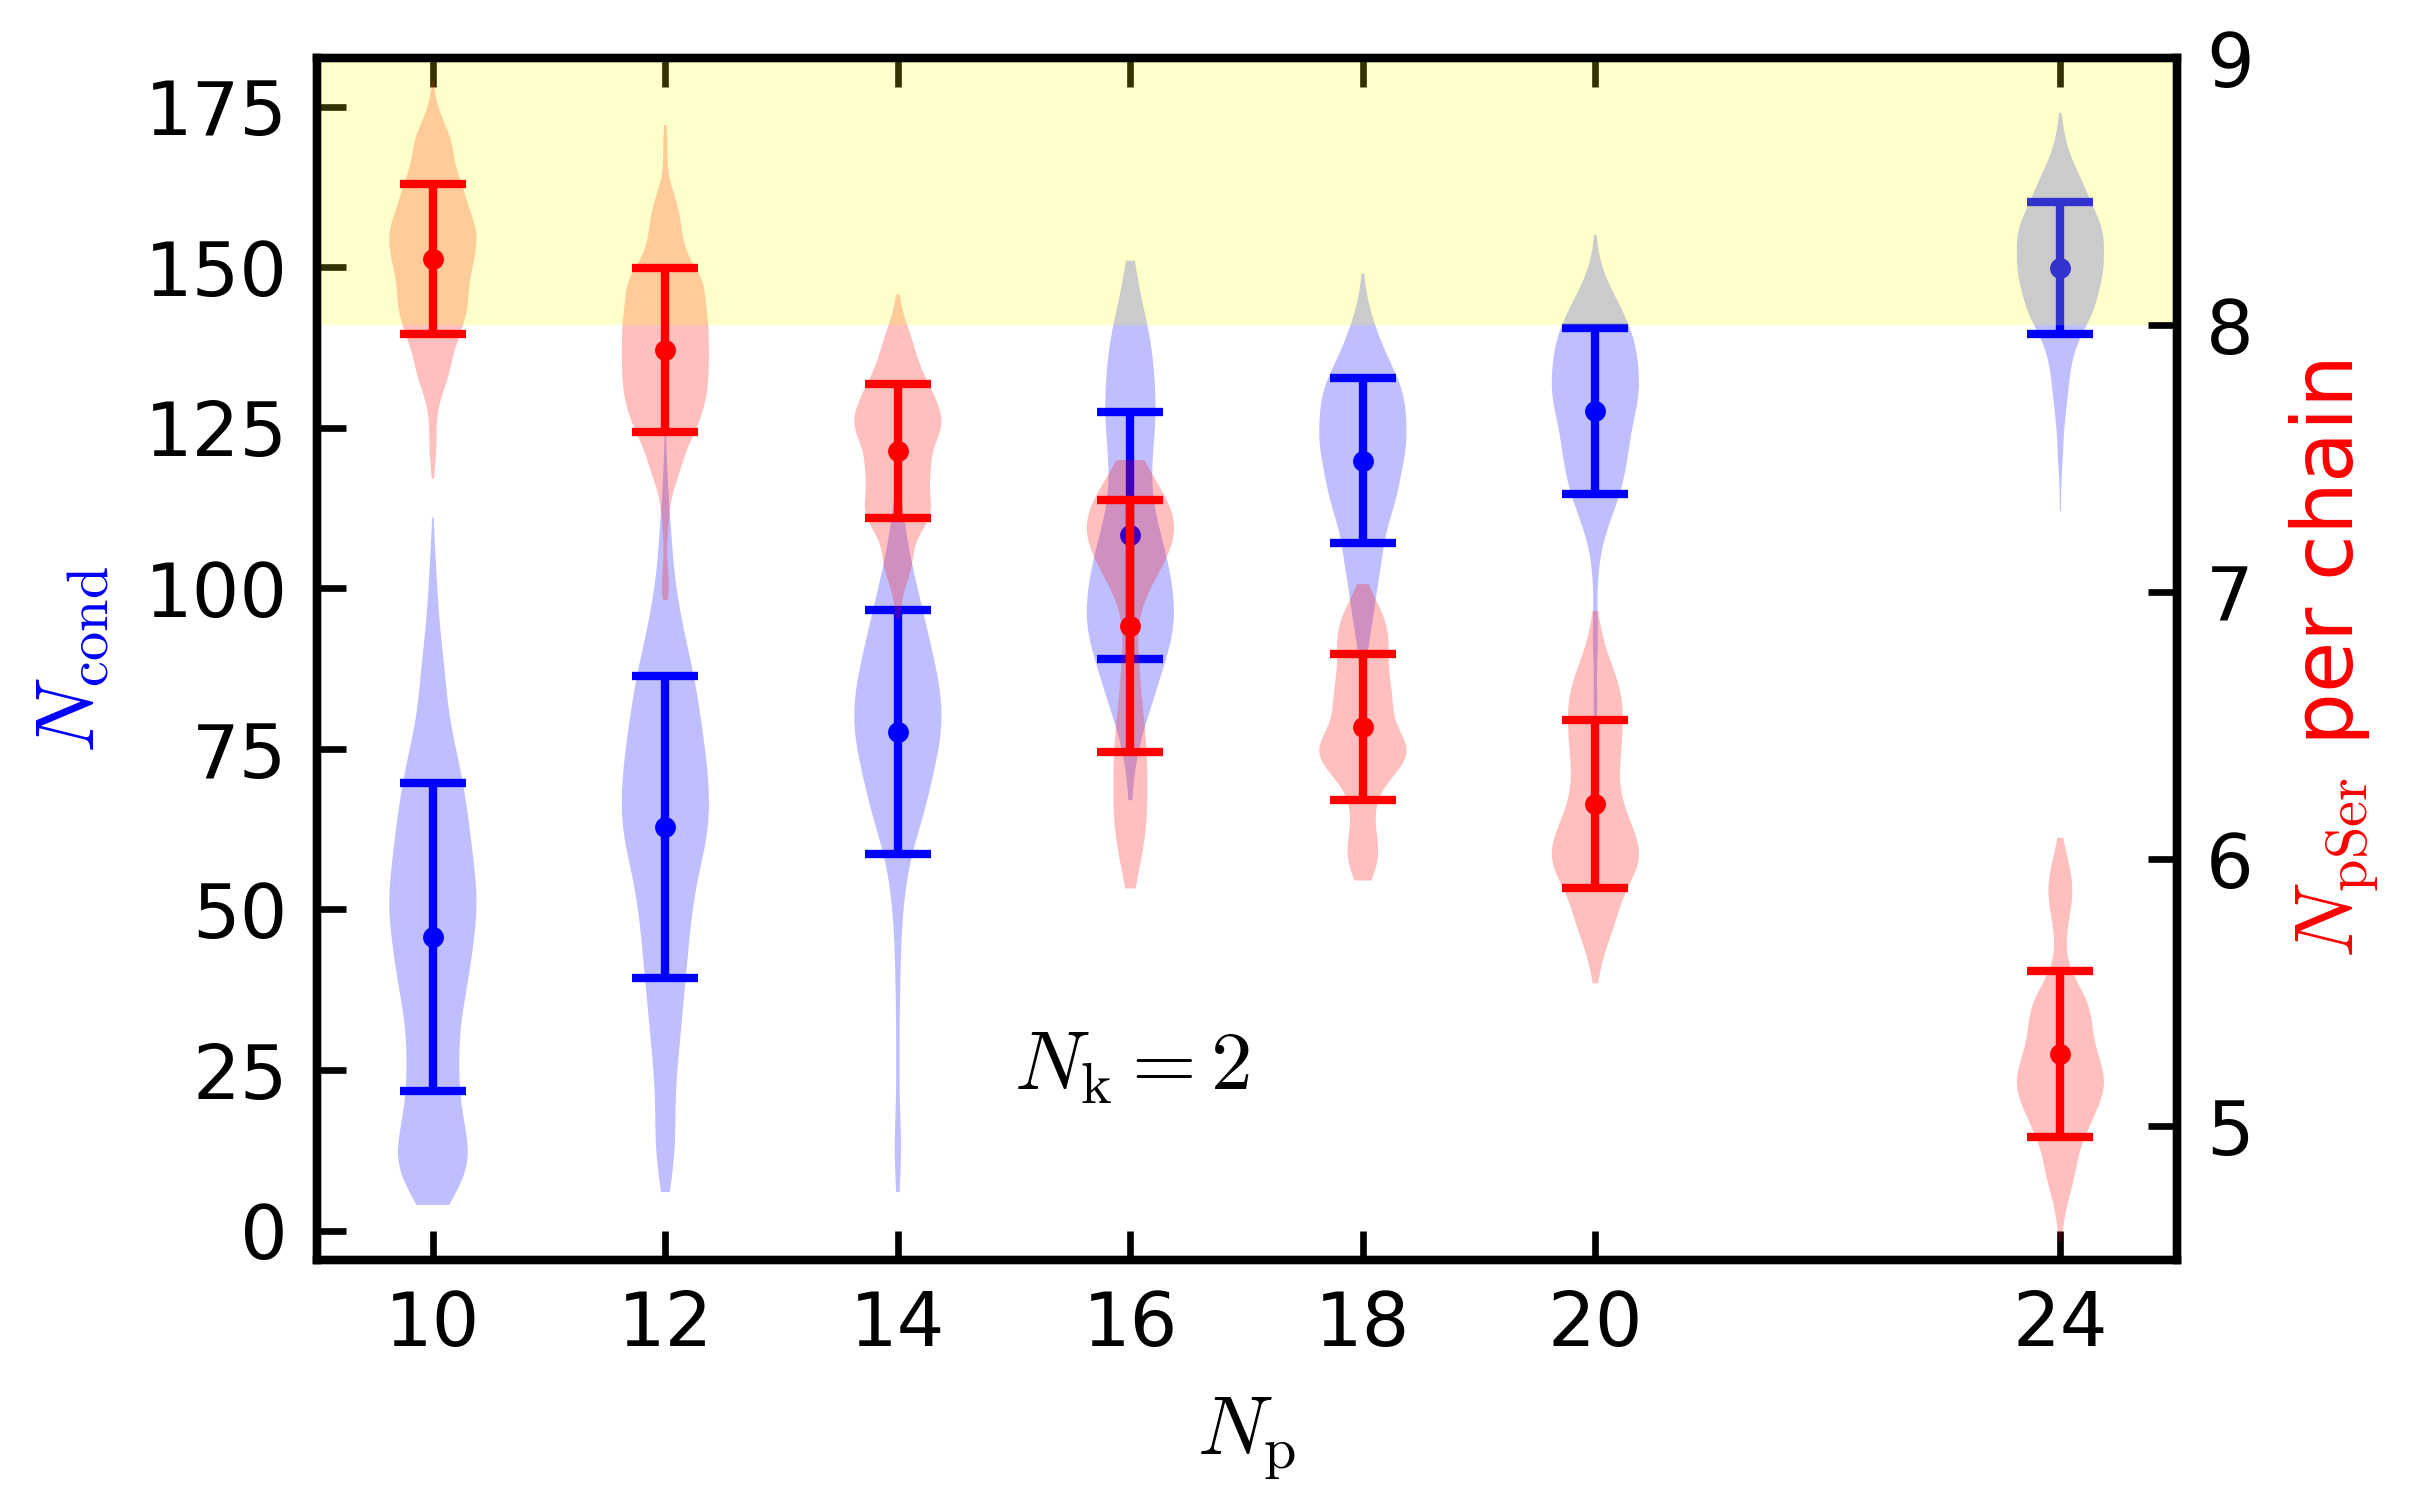

In [36]:
n_k = 2
npp3_l = [10, 12, 14, 16, 18, 20, 24]
therm_frames = [0, 0, 5000, 5000, 5000, 2500, 5000]

data = [load_size_cond(n_k, n_p, th) for n_p, th in zip(npp3_l, therm_frames)]
cs_l = [d[:, 1] for d in data]
np_l = [d[:, 2] / N_CHAINS for d in data]

fig, ax1 = plt.subplots(1, 1, figsize=(4, 2.6))
ax11 = ax1.twinx()
violins(ax1, cs_l, npp3_l, 'blue')
violins(ax11, np_l, npp3_l, 'red')
plt.fill_between([8, 26], [8, 8], [10, 10], color='yellow', alpha=0.2, lw=0.)
ax1.errorbar(npp3_l, [np.mean(x) for x in cs_l], [np.std(x) for x in cs_l], fmt='.', capsize=4, color='b')
ax11.errorbar(npp3_l, [np.mean(x) for x in np_l], [np.std(x) for x in np_l], fmt='.', capsize=4, color='r')
ax1.set_xlabel(r'$N_{\mathrm{p}}$')
ax1.set_ylabel(r'$N_{\mathrm{cond}}$', color='b')
ax11.set_ylabel(r'$N_{\mathrm{pSer}}$ per chain', color='r')
ax1.text(15, 22, r'$N_{\mathrm{k}}=2$')
ax1.set_xticks(npp3_l)
plt.xlim(9, 25)
plt.ylim(4.5, 9)
savefig(path_drop_fr_pl + 'phase_diagram_drop_cond_size_nPP3', dpi=600)

## Phase diagram of the simulations

In [37]:
# (N_k, N_p): thermalization in dump frames
PHASES = {
    'condensed':   {(2, 14): 5000, (2, 16): 5000, (2, 18): 5000, (2, 20): 2500, (2, 24): 5000, (3, 18): 2500},
    'dissolved':   {(3, 8): 2500, (4, 8): 5000},
    'oscillating': {(2, 10): 0, (2, 12): 0, (3, 12): 0, (3, 15): 2500, (4, 14): 5000, (4, 20): 1000},
}
MARKERS = {'condensed': ('o', 80), 'oscillating': ('^', 80), 'dissolved': ('s', 50)}

phase_data = {}
for phase, runs_phase in PHASES.items():
    data = {(n_k, n_p): load_size_cond(n_k, n_p, th) for (n_k, n_p), th in runs_phase.items()}
    phase_data[phase] = dict(N_kinase=np.array([k for k, _ in data]), N_phosphatase=np.array([p for _, p in data]),
                             mean_size=np.array([np.mean(d[:, 1]) for d in data.values()]),
                             mean_phosphorylation=np.array([np.mean(d[:, 2]) / N_CHAINS for d in data.values()]))


def scatter_phases(x, y, color, cmap, figsize, colorbar_label):
    plt.figure(figsize=figsize)
    vmin = min(d[color].min() for d in phase_data.values())
    vmax = max(d[color].max() for d in phase_data.values())
    for phase in ['condensed', 'oscillating', 'dissolved']:
        d = phase_data[phase]
        marker, size = MARKERS[phase]
        plt.scatter(d[x], d[y], c=d[color], cmap=cmap, s=size, marker=marker, edgecolor='k', vmin=vmin, vmax=vmax, label=phase)
    plt.colorbar(label=colorbar_label)

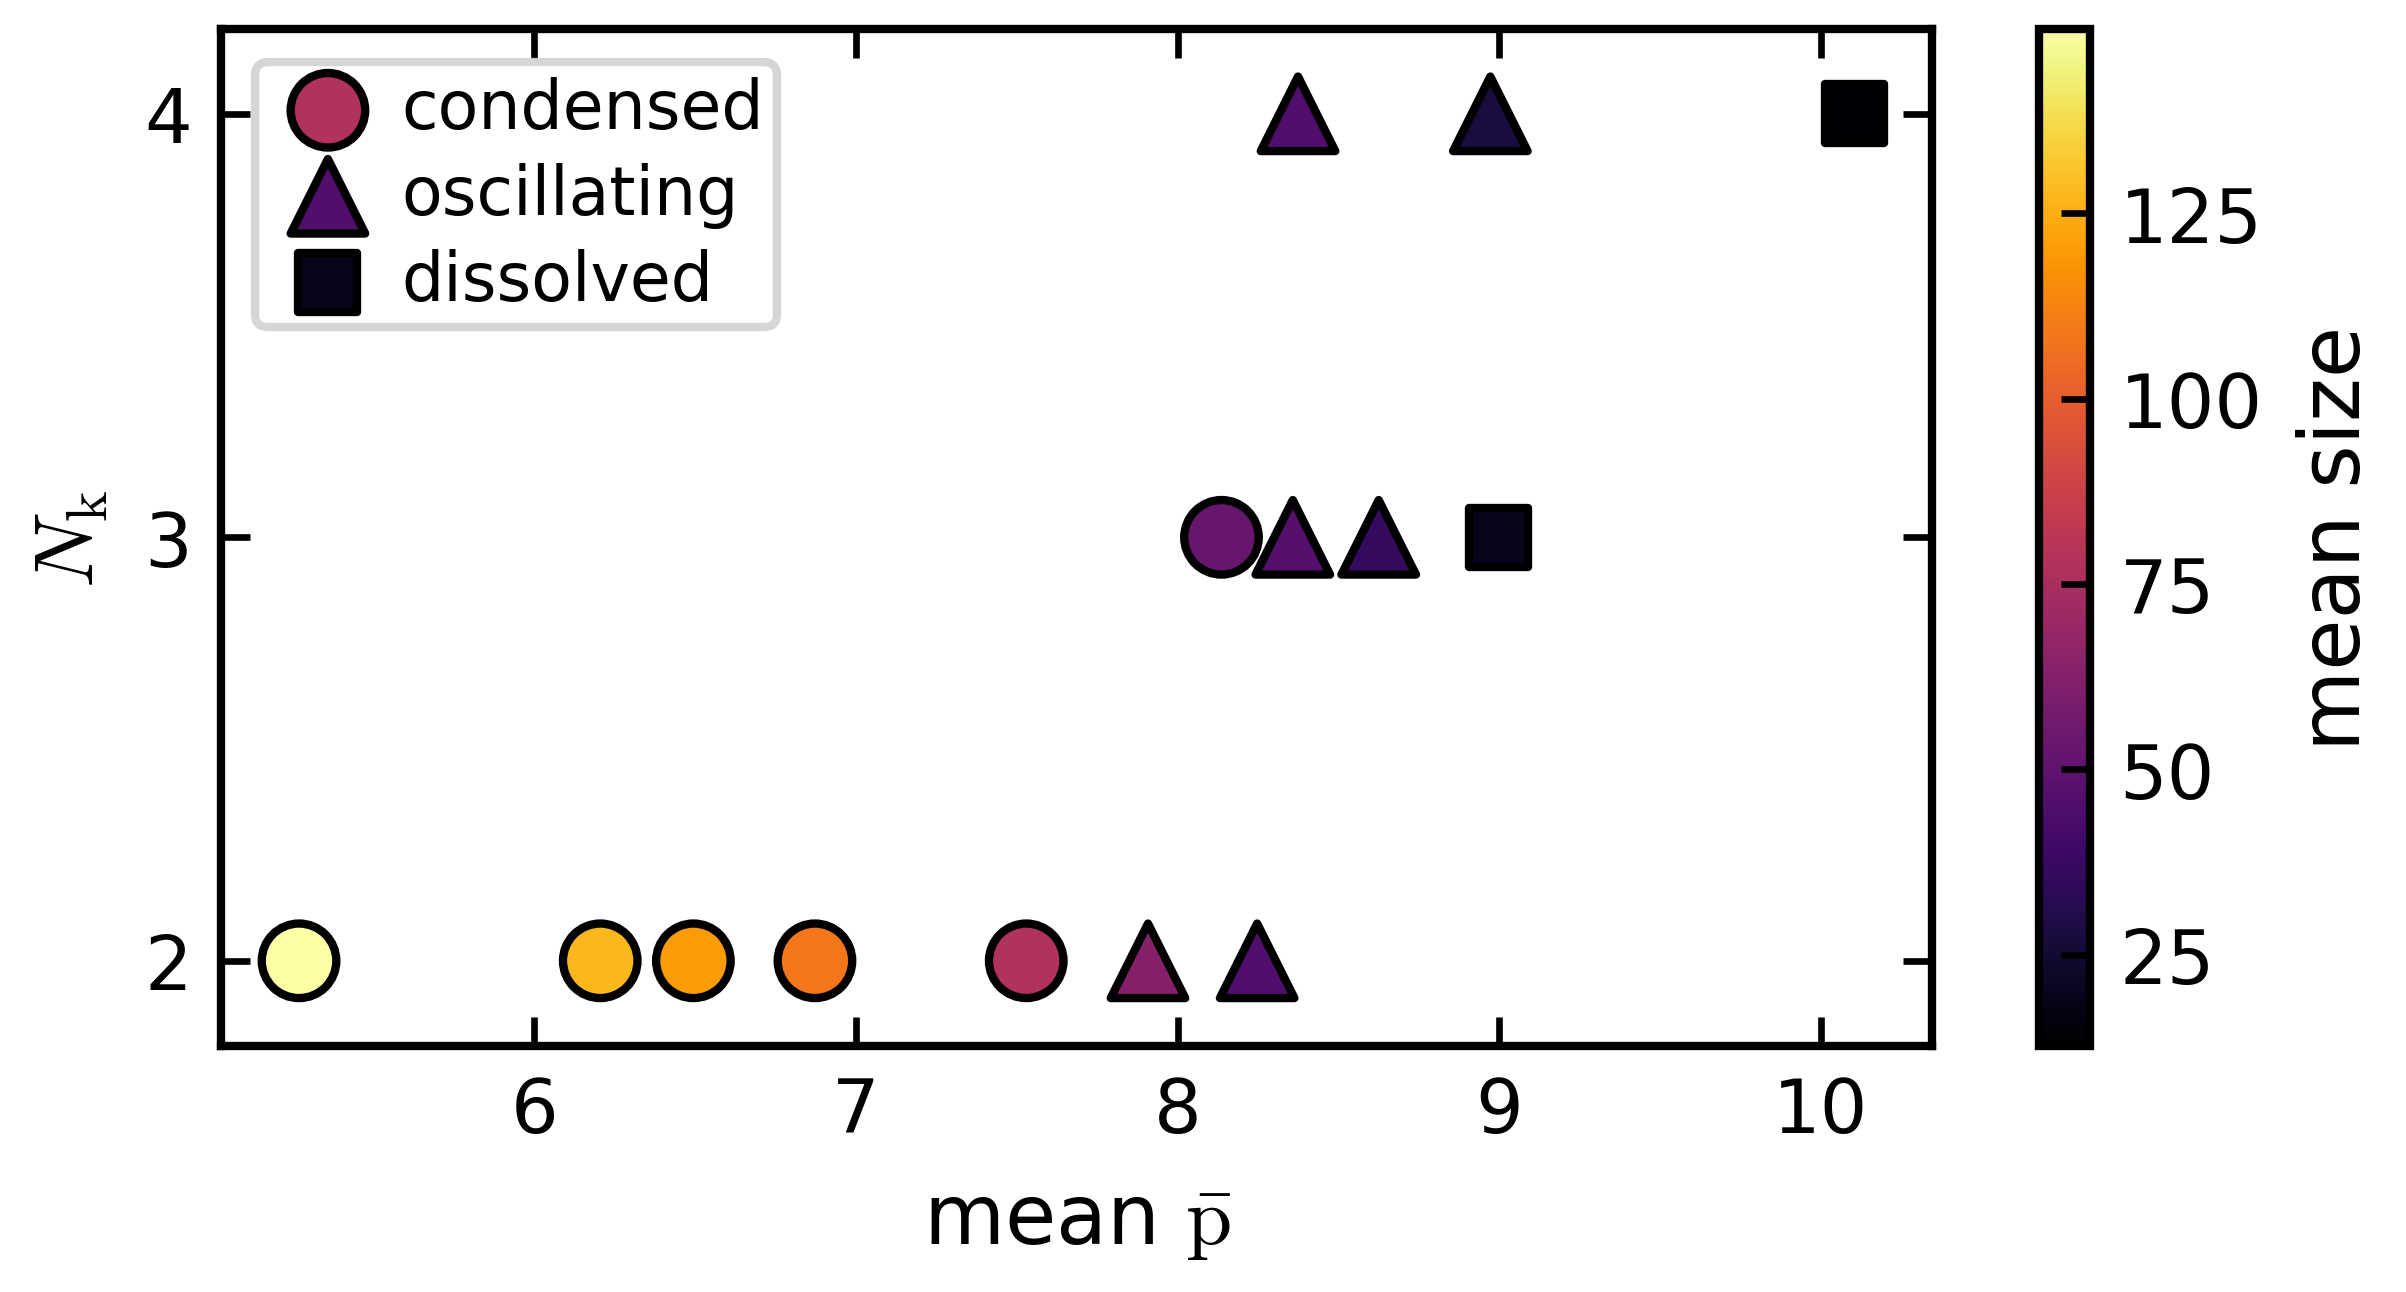

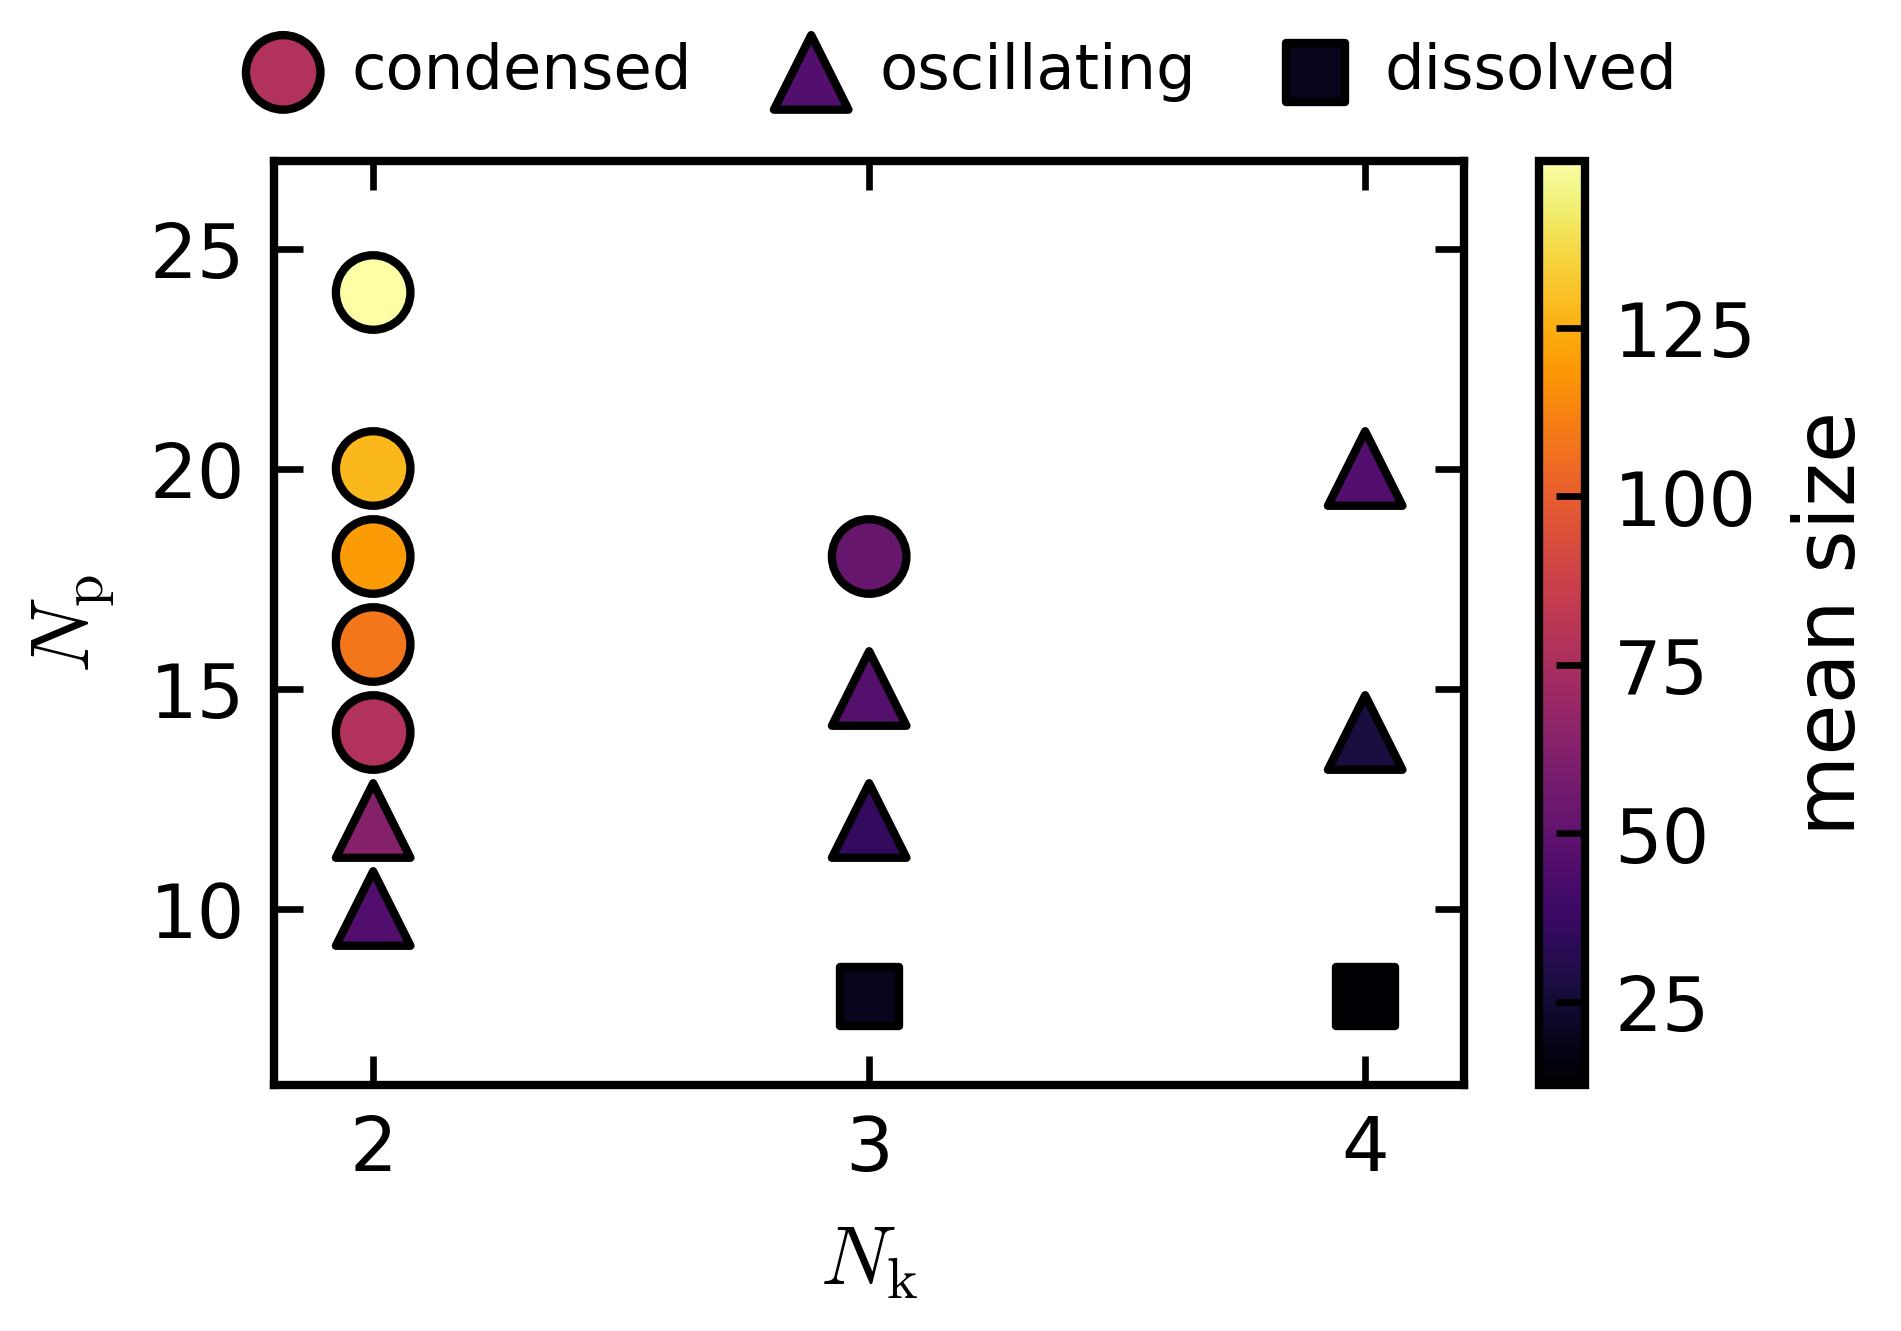

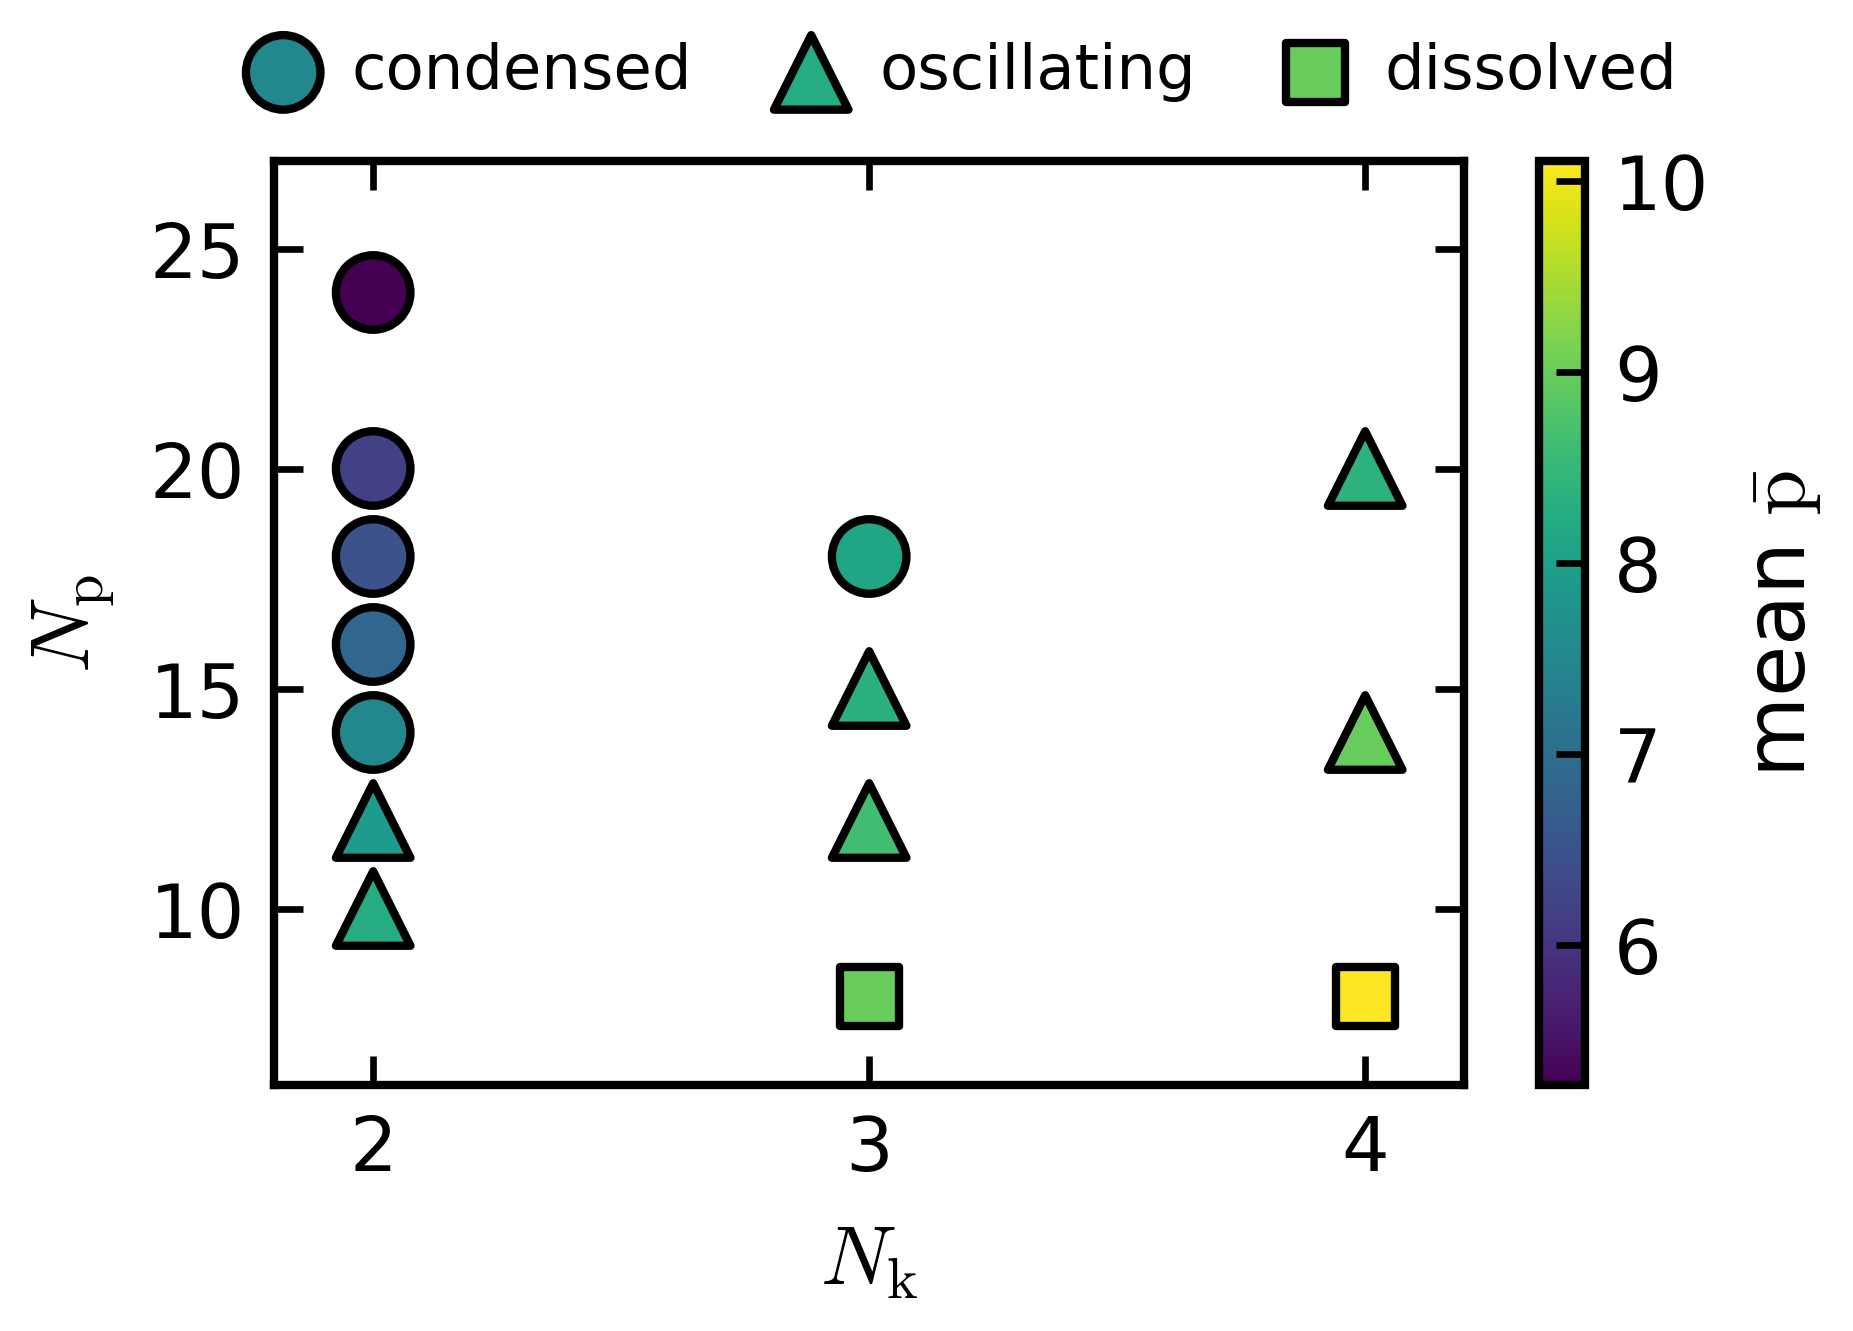

In [40]:
scatter_phases('mean_phosphorylation', 'N_kinase', 'mean_size', 'inferno', (4.6, 2.2), 'mean size')
plt.legend()
plt.xlabel(r'mean $\bar{\mathrm{p}}$')
plt.ylabel(r'$N_{\mathrm{k}}$')
plt.yticks([2, 3, 4], [2, 3, 4])
plt.ylim(1.8, 4.2)
savefig(path_drop_fr_pl + 'p_bar_vs_Nk_phase_diagram_simulations', dpi=300)

for color, cmap, label, name in [('mean_size', 'inferno', 'mean size', 'mean_cond_size'),
                                 ('mean_phosphorylation', 'viridis', r'mean $\bar{\mathrm{p}}$', 'mean_p')]:
    scatter_phases('N_kinase', 'N_phosphatase', color, cmap, (3.2, 2), label)
    plt.legend(ncols=3, loc=(-0.05, 1.05), framealpha=0, fontsize=7.5)
    plt.ylabel(r'$N_{\mathrm{p}}$')
    plt.xlabel(r'$N_{\mathrm{k}}$')
    plt.xticks([2, 3, 4], [2, 3, 4])
    plt.ylim(6, 27)
    plt.xlim(1.8, 4.2)
    savefig(path_drop_fr_pl + f'{name}_phase_diagram_simulations', dpi=600)

# 4. Oscillations
Cross-correlation of the detrended n_pSer and cluster size; period from the sliding-window cross-correlation peaks.

In [3]:
DT_ROW = 20 * DT_SNAP / 1e8   # time between rows of the size files [1e8 steps]


def period_from_sliding(C, window, dt=DT_ROW, prominence=0.1):
    '''Distance between the closest peaks at negative and positive lag in every window (nan if missing).'''
    period = []
    for row in C:
        left, _ = signal.find_peaks(row[:window], prominence=prominence)
        right, _ = signal.find_peaks(row[window:], prominence=prominence)
        period.append((right[0] + window - left[-1]) * dt if len(left) and len(right) else np.nan)
    return np.array(period)


def load_oscillation(n_k, n_p, ss, therm=0, sim_type='ness'):
    times, cond_size, n_pser = read_chains_in_condensate(path_drop_fr_an, N_CHAINS, n_k, n_p, sim_type, ss)
    mask = times > therm
    return times[mask], cond_size[mask], n_pser[mask]


def label_enzymes(ax, x, y, n_k, n_p):
    ax.text(x, y, r'N$_{\mathrm{k}}$=' + f'{n_k}' + '\n' + r'N$_{\mathrm{p}}$=' + f'{n_p}')


def plot_cross_correlations(ax, n_k, n_p, therm=0, xlabel=r'Lag [$\times 10^8$ steps]', ylabel='Cross-correlation'):
    min_corr = min_lag = 0
    for ss in SIMS:
        times, cond_size, n_pser = load_oscillation(n_k, n_p, ss, therm)
        lags, corr = cross_correlation(signal.detrend(n_pser), signal.detrend(cond_size))
        lags = lags * (times[1] - times[0]) / 1e8
        min_corr, min_lag = min(min_corr, corr.min()), min(min_lag, lags.min())
        ax.plot(lags, corr)
    ax.axhline(0, color='k', ls='--')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    label_enzymes(ax, min_lag, min_corr * 0.9, n_k, n_p)


def plot_sliding_correlation_peak_distance(ax, n_k, n_p, window=400, step=20, therm=0, xlabel='Window time', ylabel='Period'):
    min_t = min_p = 0
    for ss in SIMS:
        times, cond_size, n_pser = load_oscillation(n_k, n_p, ss, therm)
        C, _, times_slide = sliding_window_correlation(n_pser, cond_size, window, step, dt=DT_ROW)
        period = period_from_sliding(C, window)
        ok = np.isfinite(period)
        ax.plot(times_slide[ok], period[ok])
        min_t, min_p = min(min_t, times_slide[ok].min()), min(min_p, period[ok].min())
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    label_enzymes(ax, min_t, min_p, n_k, n_p)


def correlation_grid(plot, panels, filename):
    '''3x2 grid; panels = [((row, col), n_k, n_p, kwargs), ...].'''
    f, ax = plt.subplots(3, 2, figsize=(6.5, 5))
    for k, color in enumerate(['tab:blue', 'tab:orange', 'tab:green']):
        ax[0, 0].plot([], [], c=color, label=f'replica{k + 1}')
    ax[0, 0].legend(loc=(0.6, 1.1), framealpha=0, ncols=3)
    for (i, j), n_k, n_p, kwargs in panels:
        plot(ax[i, j], n_k, n_p, **kwargs)
    savefig(path_drop_fr_pl + filename, dpi=600)

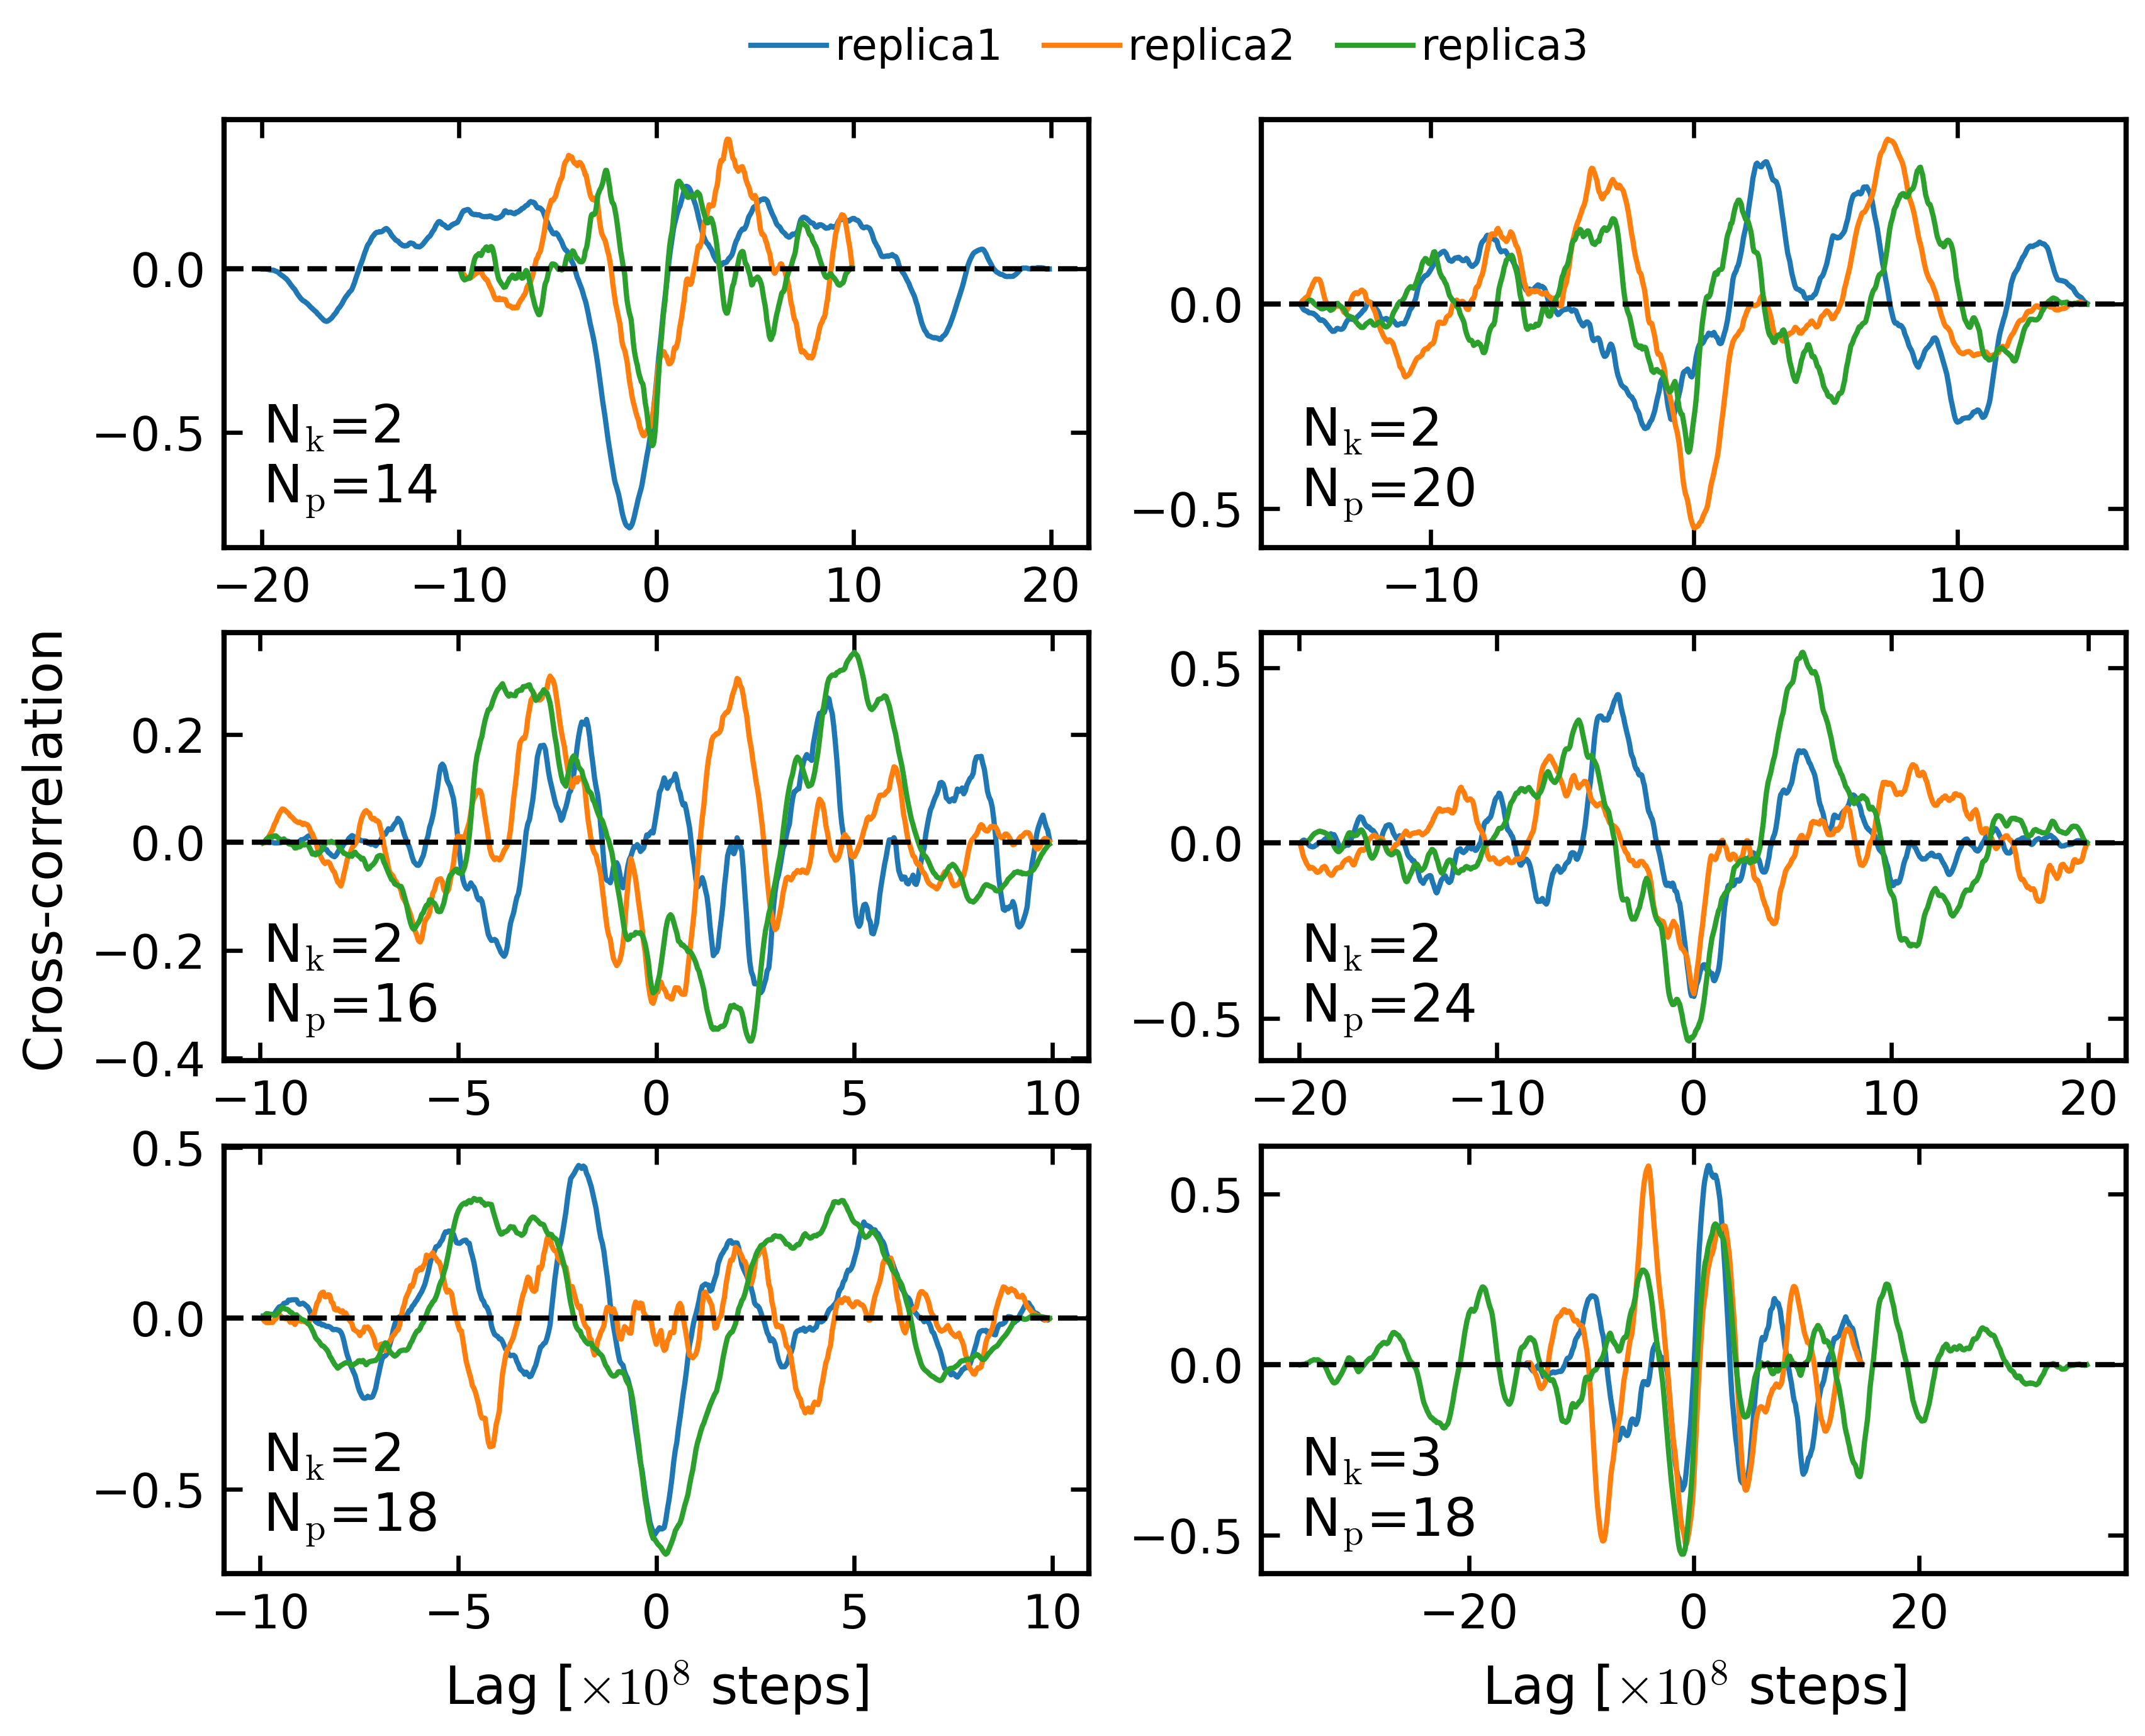

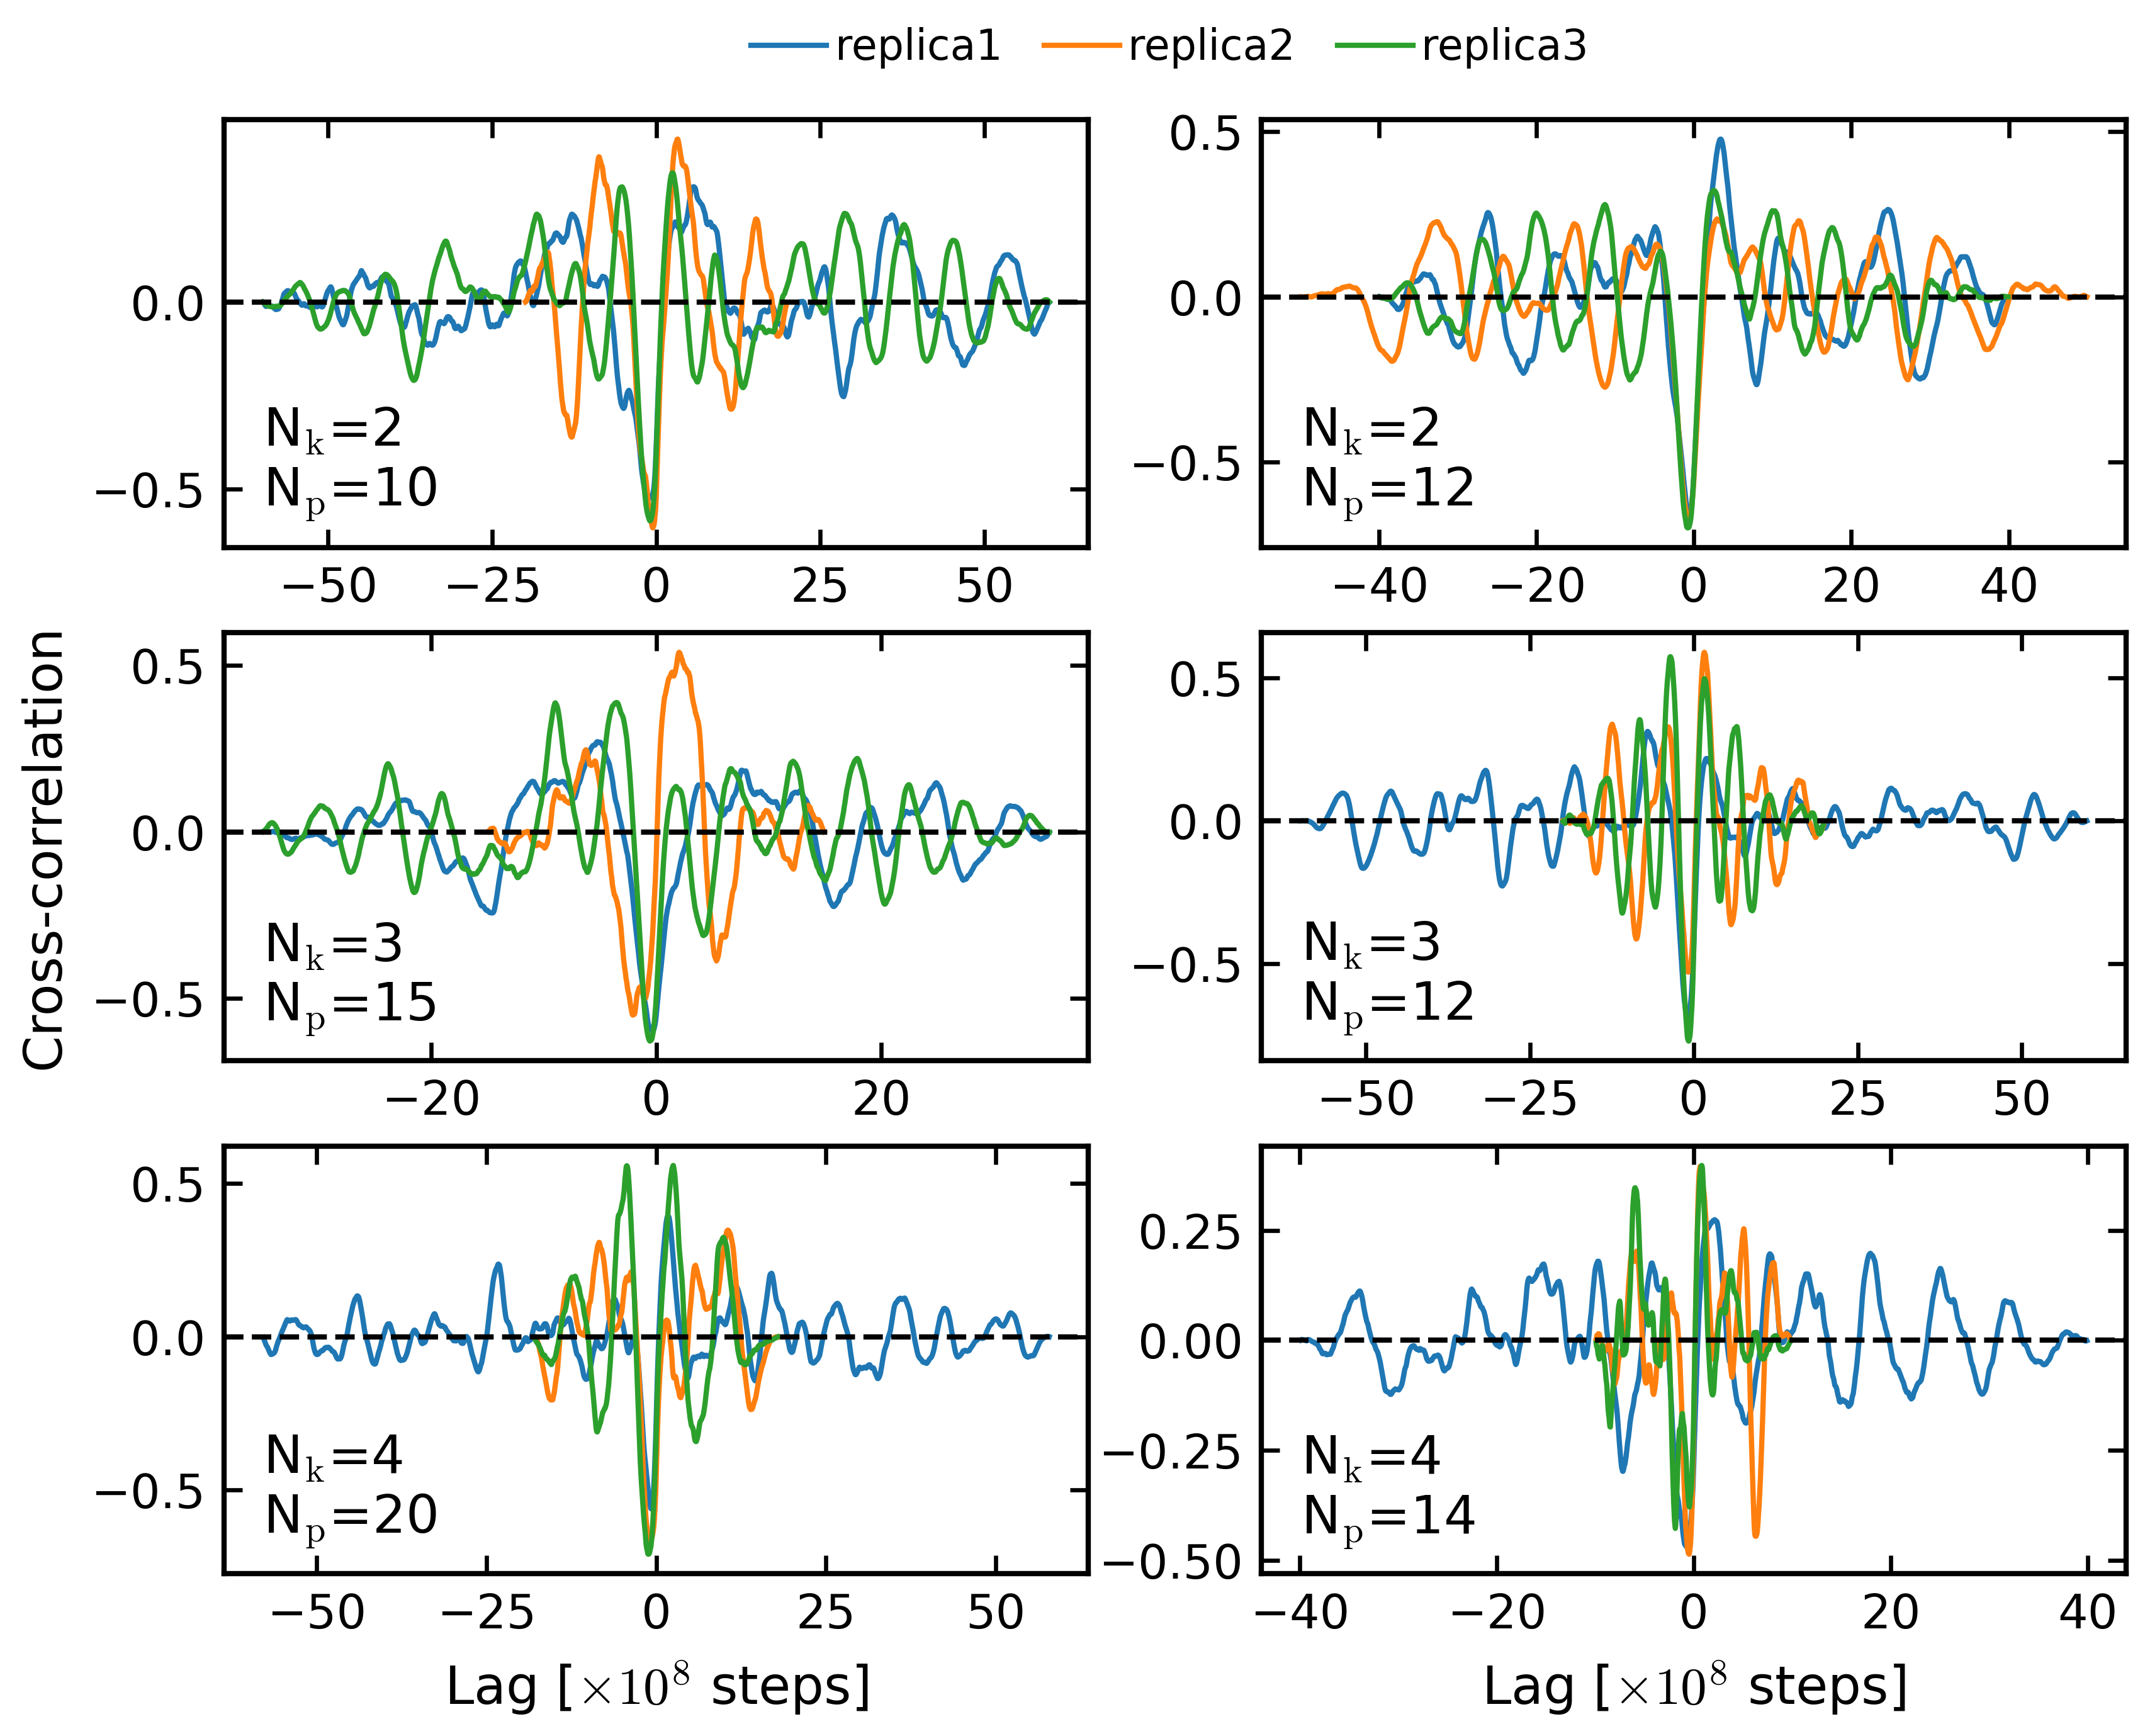

In [4]:
no_x, no_y, none = dict(xlabel=None), dict(ylabel=None), dict(xlabel=None, ylabel=None)

correlation_grid(plot_cross_correlations,
                 [((0, 0), 2, 14, dict(therm=10e8, **none)), ((1, 0), 2, 16, dict(therm=10e8, **no_x)),
                  ((2, 0), 2, 18, dict(therm=10e8, **no_y)), ((0, 1), 2, 20, dict(therm=5e8, **none)),
                  ((1, 1), 2, 24, dict(therm=10e8, **none)), ((2, 1), 3, 18, dict(therm=5e8, **no_y))],
                 'cross_correlation_non-oscillating_drop_cond_size_npser')

oscillating = [((0, 0), 2, 10, none), ((1, 0), 3, 15, dict(therm=5e8, **no_x)), ((2, 0), 4, 20, dict(therm=2e8, **no_y)),
               ((0, 1), 2, 12, none), ((1, 1), 3, 12, none), ((2, 1), 4, 14, dict(therm=10e8, **no_y))]
correlation_grid(plot_cross_correlations, oscillating, 'cross_correlation_oscillations_drop_cond_size_npser')


## Single oscillating replica

504000000.0 5996000000.0


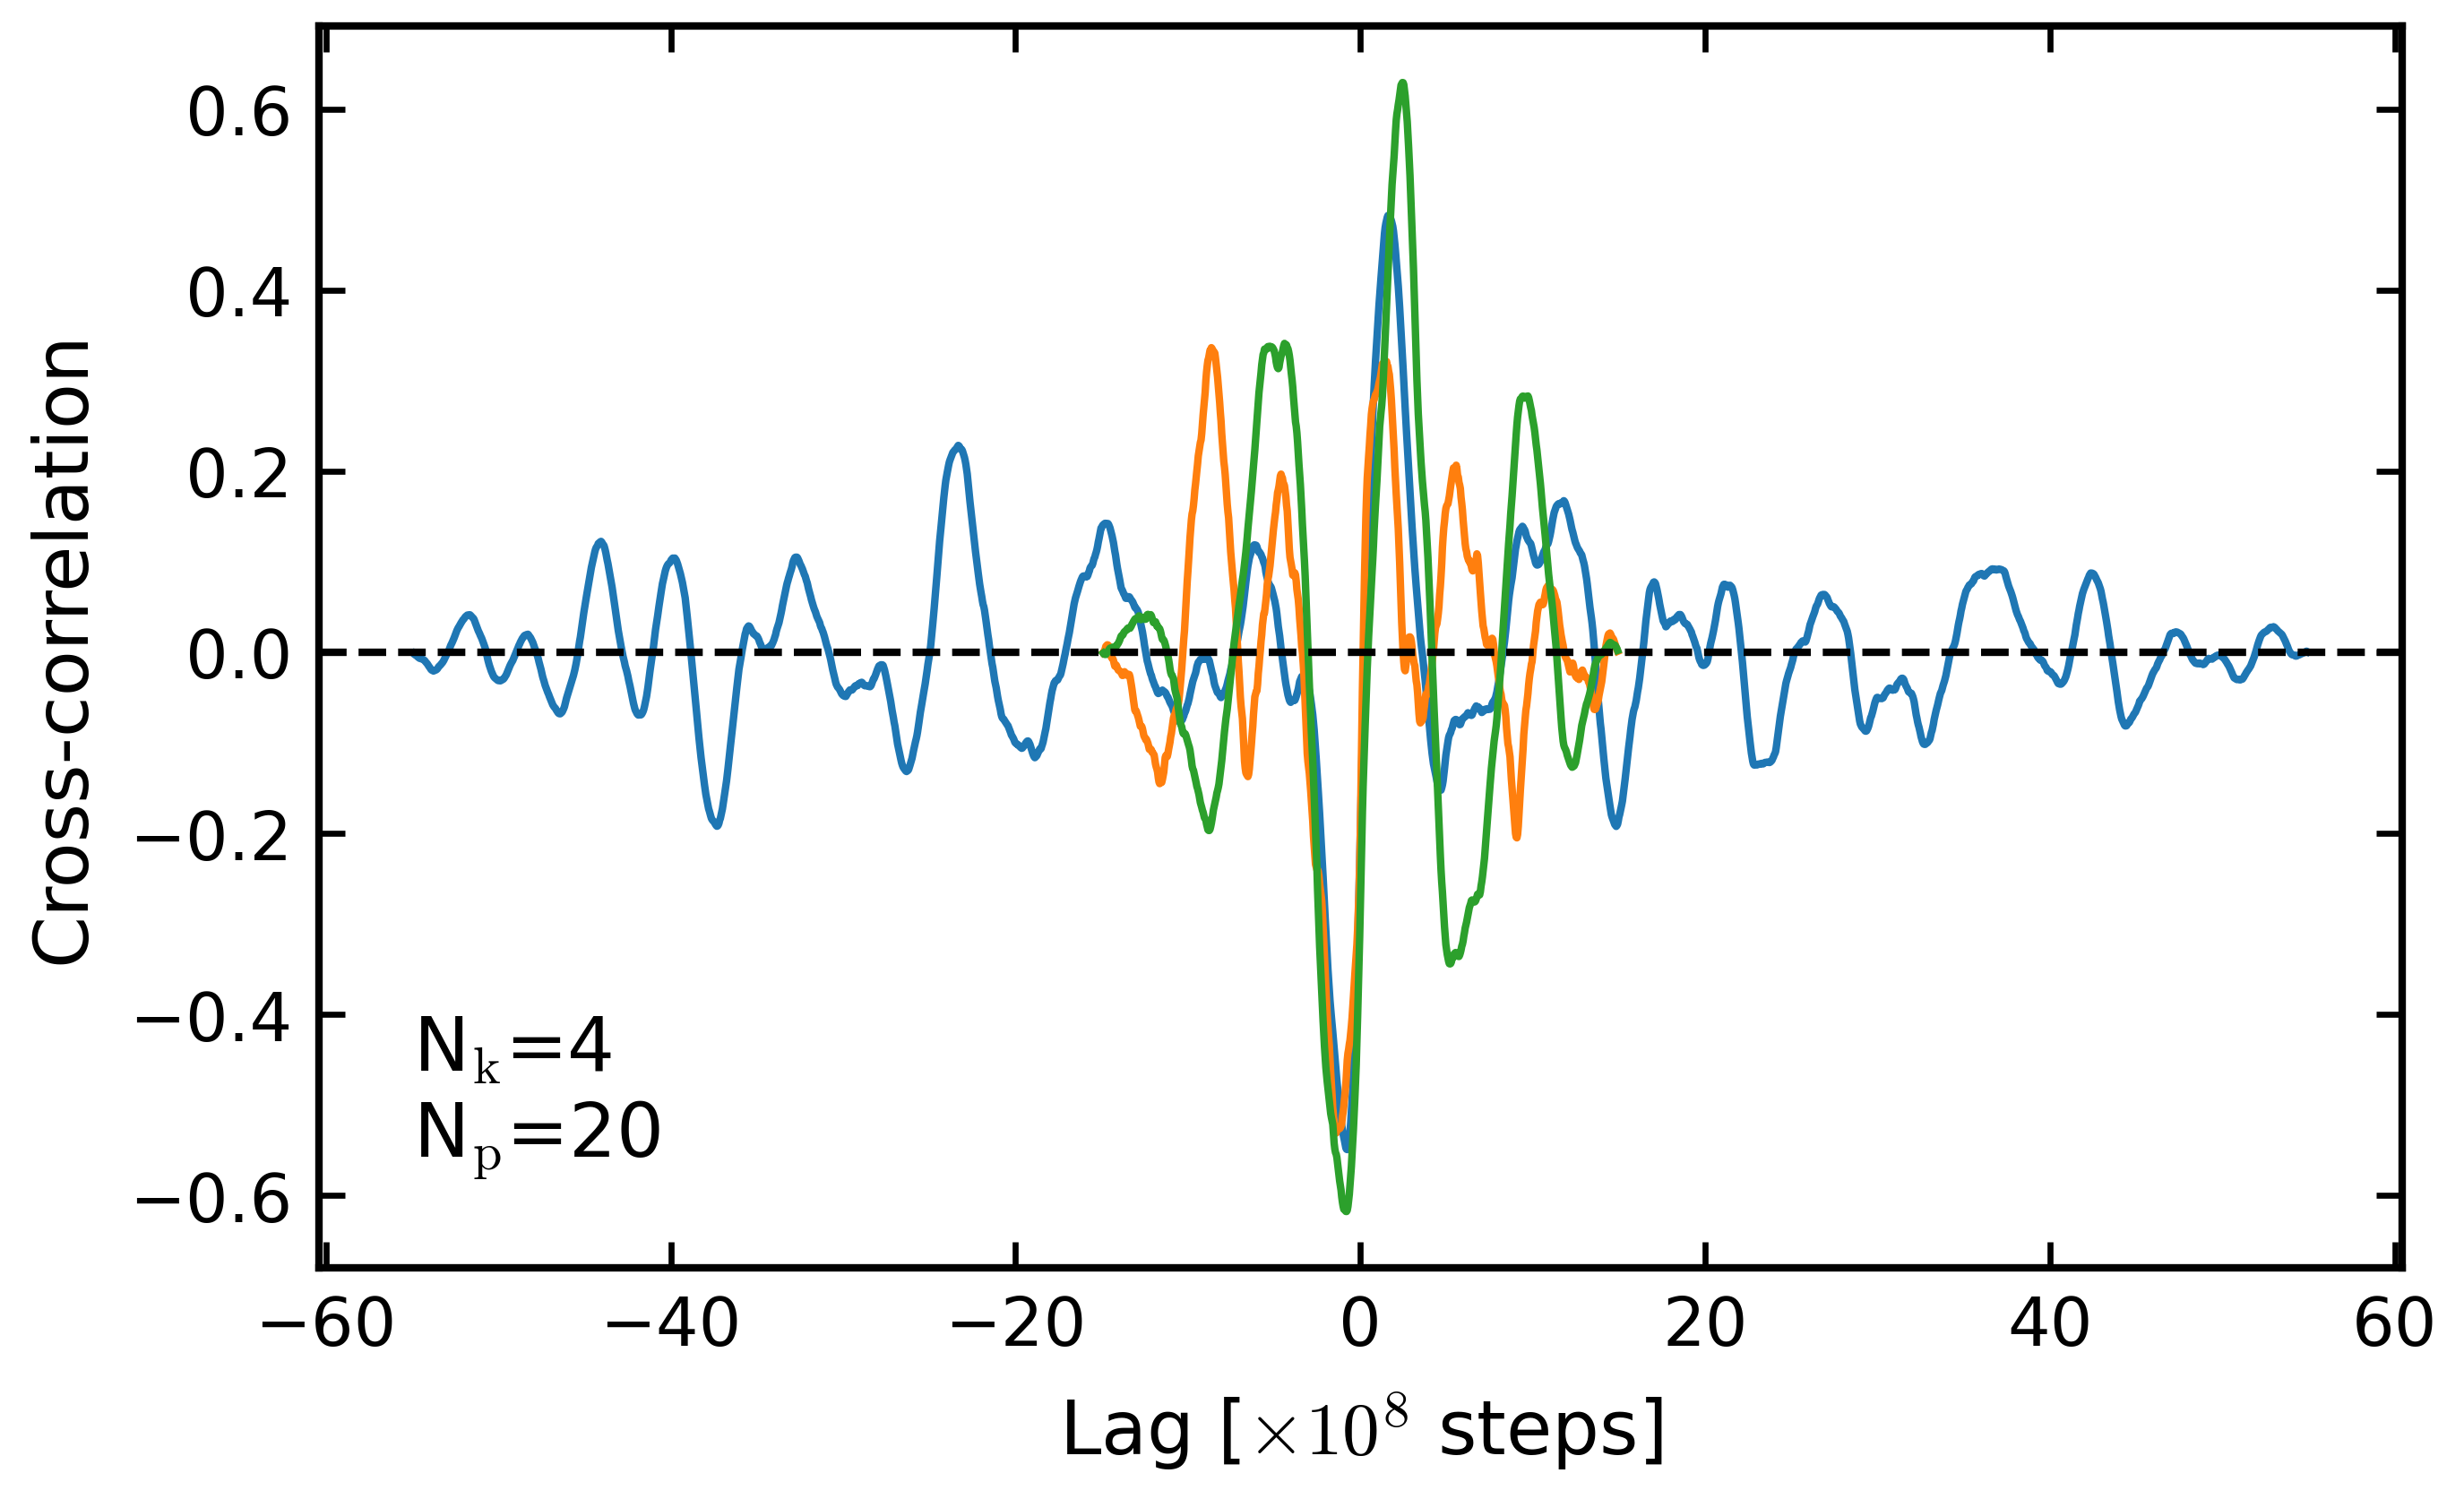

In [44]:
n_k, n_p, ss = 4, 20, 1
therm = 5e8
window, step = 400, 20
fig_prefix = path_drop_fr_pl + f'{drop_name("ness", n_k, n_p)}/sim{ss}_'
name = f'200-tdp-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01'

f, ax = plt.subplots(figsize=(5, 3))
plot_cross_correlations(ax, n_k, n_p, therm=therm)

times, cond_size, n_pser = load_oscillation(n_k, n_p, ss, therm)
print(times[0], times[-1])
lags, corr = cross_correlation(signal.detrend(n_pser), signal.detrend(cond_size))
lags = lags * (times[1] - times[0]) / 1e8
C, lags_slide, times_slide = sliding_window_correlation(n_pser, cond_size, window, step, dt=DT_ROW)
period = period_from_sliding(C, window)

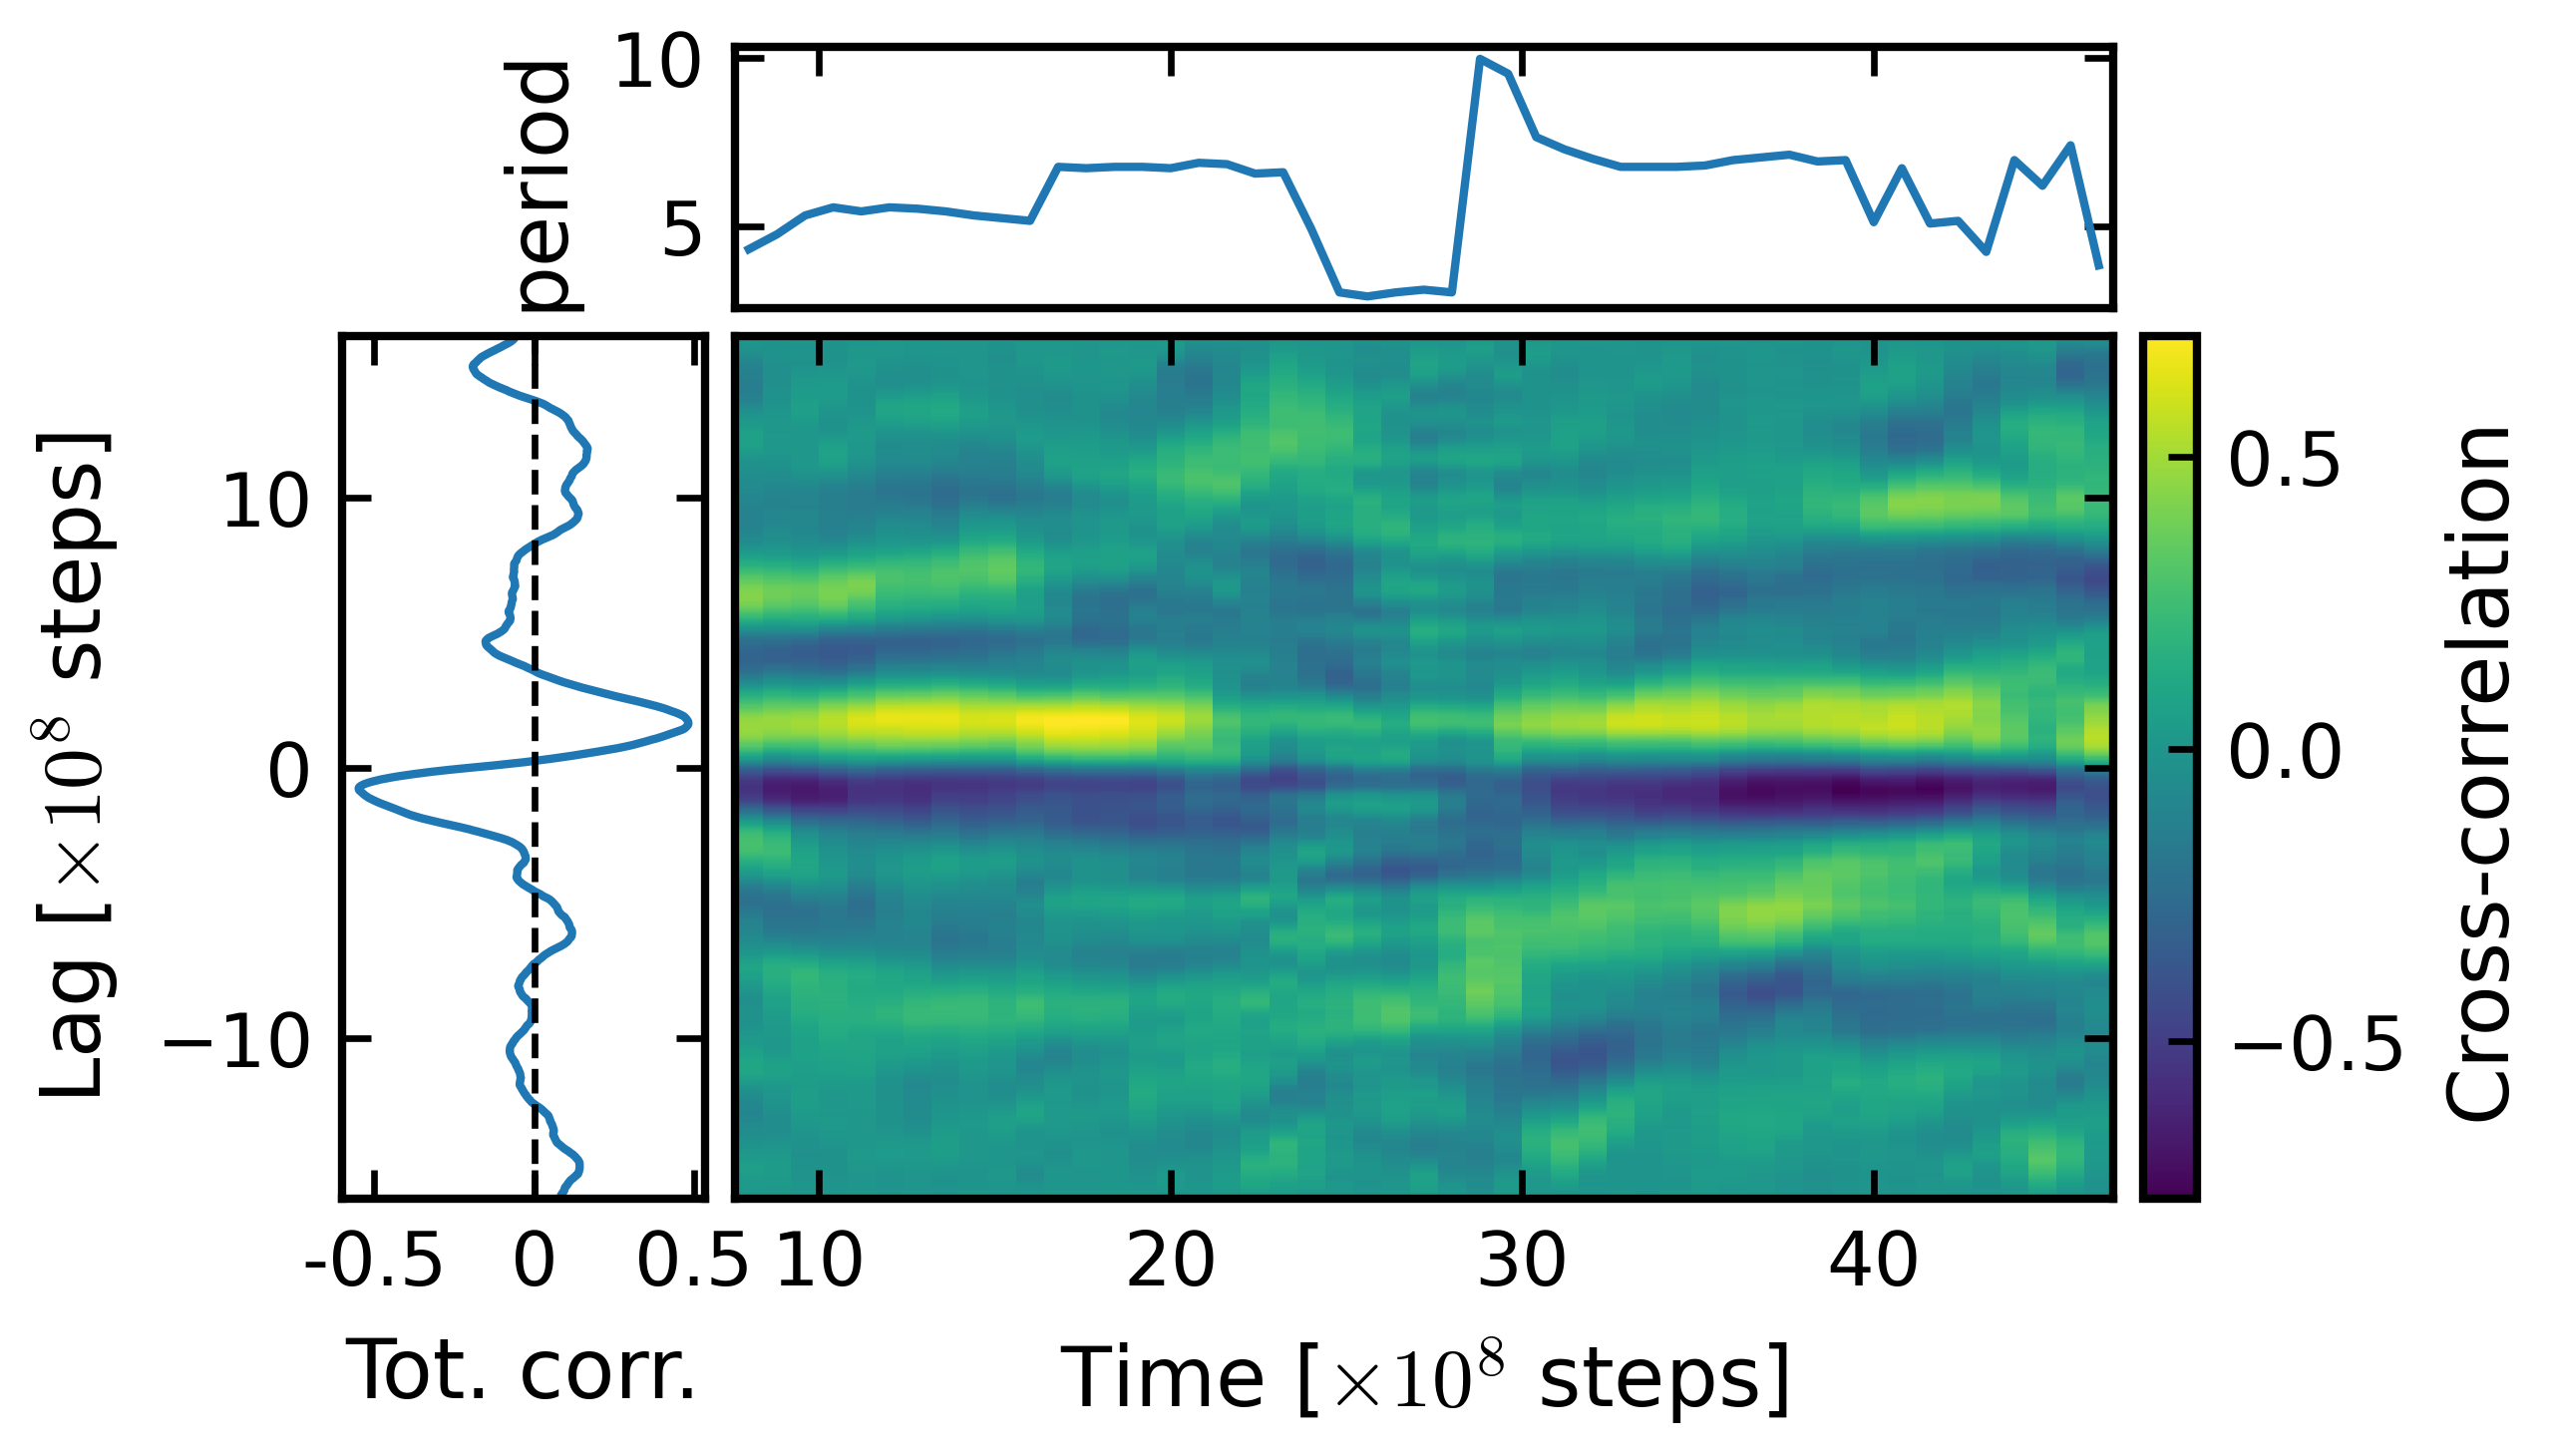

In [50]:
def plot_sliding_map(fig, gs_row, show_period):
    ax = fig.add_subplot(gs[gs_row, 1])
    pcm = ax.pcolormesh(times_slide, lags_slide, C.T, shading='auto')
    #ax.axhline(0, linestyle='--', linewidth=1)
    ax.set_xlabel(r'Time [$\times 10^8$ steps]')
    ax.set_ylim(lags_slide.min(), lags_slide.max())
    ax.tick_params(axis='y', left=False, labelleft=False)

    ax_total = fig.add_subplot(gs[gs_row, 0], sharey=ax)
    ax_total.plot(corr, lags)
    ax_total.axvline(0, linestyle='--', linewidth=0.8, color='k')
    ax_total.set_ylabel(r'Lag [$\times 10^8$ steps]')
    ax_total.set_xlabel('Tot. corr.')
    ax_total.set_xticks([-0.5, 0, 0.5], [-0.5, 0, 0.5])
    ax_total.set_ylim(ax.get_ylim())

    fig.colorbar(pcm, cax=fig.add_subplot(gs[gs_row, 2])).set_label('Cross-correlation')
    if show_period:
        ax_dt = fig.add_subplot(gs[0, 1], sharex=ax)
        ax_dt.plot(times_slide, period)
        ax_dt.set_ylabel('period')
        ax_dt.tick_params(axis='x', bottom=False, labelbottom=False)


fig = plt.figure(figsize=(4., 2.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 3.8, 0.15], height_ratios=[1, 3.3], wspace=0.05, hspace=0.05)
plot_sliding_map(fig, 1, show_period=True)
savefig(fig_prefix + f'cross-correlation_{name}', dpi=300)


# 5. Limit cycles

In [5]:
def plot_limit_cycles(n_chains, n_chains_enz1, n_chains_enz2, n_sims, sim_type, fr='_fr01', chain_length=154, times=None, therm=0):
    '''Limit cycles of several runs; computes the size series from the dump when the size file is missing.'''
    fig, ax = plt.subplots(figsize=(4, 3.2))
    nenz1 = n_chains_enz1 if isinstance(n_chains_enz1, list) else [n_chains_enz1]
    nenz2 = n_chains_enz2 if isinstance(n_chains_enz2, list) else [n_chains_enz2]
    n_sims = n_sims if isinstance(n_sims, list) else [n_sims]
    ncolors = len(nenz1) * len(nenz2) * len(n_sims)
    colors = plt.cm.tab10(range(ncolors)) if ncolors <= 10 else plt.cm.tab20(range(ncolors))

    nc = 0
    for ne1 in nenz1:
        for ne2 in nenz2:
            for ss in n_sims:
                if Path(size_cond_file(sim_type, ne1, ne2, ss)).exists():
                    _, c_s, n_p = read_chains_in_condensate(path_drop_fr_an, n_chains, ne1, ne2, sim_type, ss, fr=fr, therm=therm)
                else:
                    print(f'{size_cond_file(sim_type, ne1, ne2, ss)} does not exist! compute limit cycle from dump file')
                    path = path_drop_fr + f'sim_{sim_type}_{n_chains}-tdp43-lcd_{ne1}-ck1d-open_{ne2}-pp3{fr}/'
                    file_suffix = f'{sim_type}_{n_chains}-tdp43-lcd_{ne1}-com-ck1d-open_{ne2}-com-pp3_CAL3{fr}'
                    c_s, n_p = hpa.cluster.chains_in_condensate(path, file_suffix + '_dump.gsd', n_sims=[ss], times=times,
                                                                n_particles=n_chains * chain_length, n_clusters=1)
                    c_s = c_s.flatten()
                plot_fading_trajectory(ax, c_s, n_p / 200, colors[nc], label='N$_p$' + f'={ne2}, rep.{ss}')
                nc += 1

    ax.autoscale()
    ax.legend()
    ax.set_xlabel(r'N$_{\mathrm{chains}}$ in cluster')
    ax.set_ylabel(r'N$_{\mathrm{pSer}}$ per chain')

In [6]:
# label: (N_k, N_p, sim_type, replica, rows to skip)
LC_RUNS = {
    '2_24': (2, 24, 'ness', 1, 250), '2_24_dmu0': (2, 24, 'dmu0', 1, 0),
    '2_14': (2, 14, 'ness', 2, 250), '2_14_dmu0': (2, 14, 'dmu0', 1, 0),
    '2_12': (2, 12, 'ness', 2, 25), '2_12_dmu0': (2, 12, 'dmu0', 1, 0),
    '2_10': (2, 10, 'ness', 3, 25), '2_10_dmu0': (2, 10, 'dmu0', 1, 0),
    '2_16': (2, 16, 'ness', 1, 250), '2_18': (2, 18, 'ness', 2, 250), '2_20': (2, 20, 'ness', 3, 125),
    '3_12': (3, 12, 'ness', 1, 25), '3_15': (3, 15, 'ness', 3, 125), '3_18': (3, 18, 'ness', 3, 125),
    '4_20': (4, 20, 'ness', 1, 50), '2_6': (2, 6, 'ness', 3, 125),
}
lc = {label: read_chains_in_condensate(path_drop_fr_an, 200, n_k, n_p, st, n_sim=ss, therm=th)
      for label, (n_k, n_p, st, ss, th) in LC_RUNS.items()}

# equilibrium droplets (no reactions): mean size vs (constant) pSer per chain
cs_eq, dcs_eq, np_eq = [], [], []
for npser in NPSER_EQ:
    data = np.concatenate([np.loadtxt(path_pser_an + f'sim{ss}_size_cond_eq_200-tdp43-lcd-{npser}pser_CAL3_fr01.dat')[25:]
                           for ss in SIMS])
    cs_eq.append(np.mean(data[:, 1]))
    dcs_eq.append(np.std(data[:, 1]))
    np_eq.append(data[0, 2] / 200)


def plot_lc(ax, run, color, **kwargs):
    _, cs, n_pser = lc[run]
    plot_fading_trajectory(ax, cs, n_pser / 200, color, **kwargs)


def driving_text(ax, x, y, dmu_k, dmu_p, dy=0.25):
    ax.text(x, y, r'$\Delta \mu_{k}=' + dmu_k + r'~\mathrm{kJ}~\mathrm{mol}^{-1}$', fontsize=8)
    ax.text(x, y - dy, r'$\Delta \mu_{p}=' + dmu_p + r'~\mathrm{kJ}~\mathrm{mol}^{-1}$', fontsize=8)


def finish_lc(ax, filename, **legend_kwargs):
    ax.autoscale()
    ax.legend(**legend_kwargs)
    ax.set_xlabel(r'$N_{\mathrm{cond}}$')
    ax.set_ylabel(r'$N_{\mathrm{pSer}}$ per chain')
    savefig(path_drop_fr_pl + filename, dpi=600)

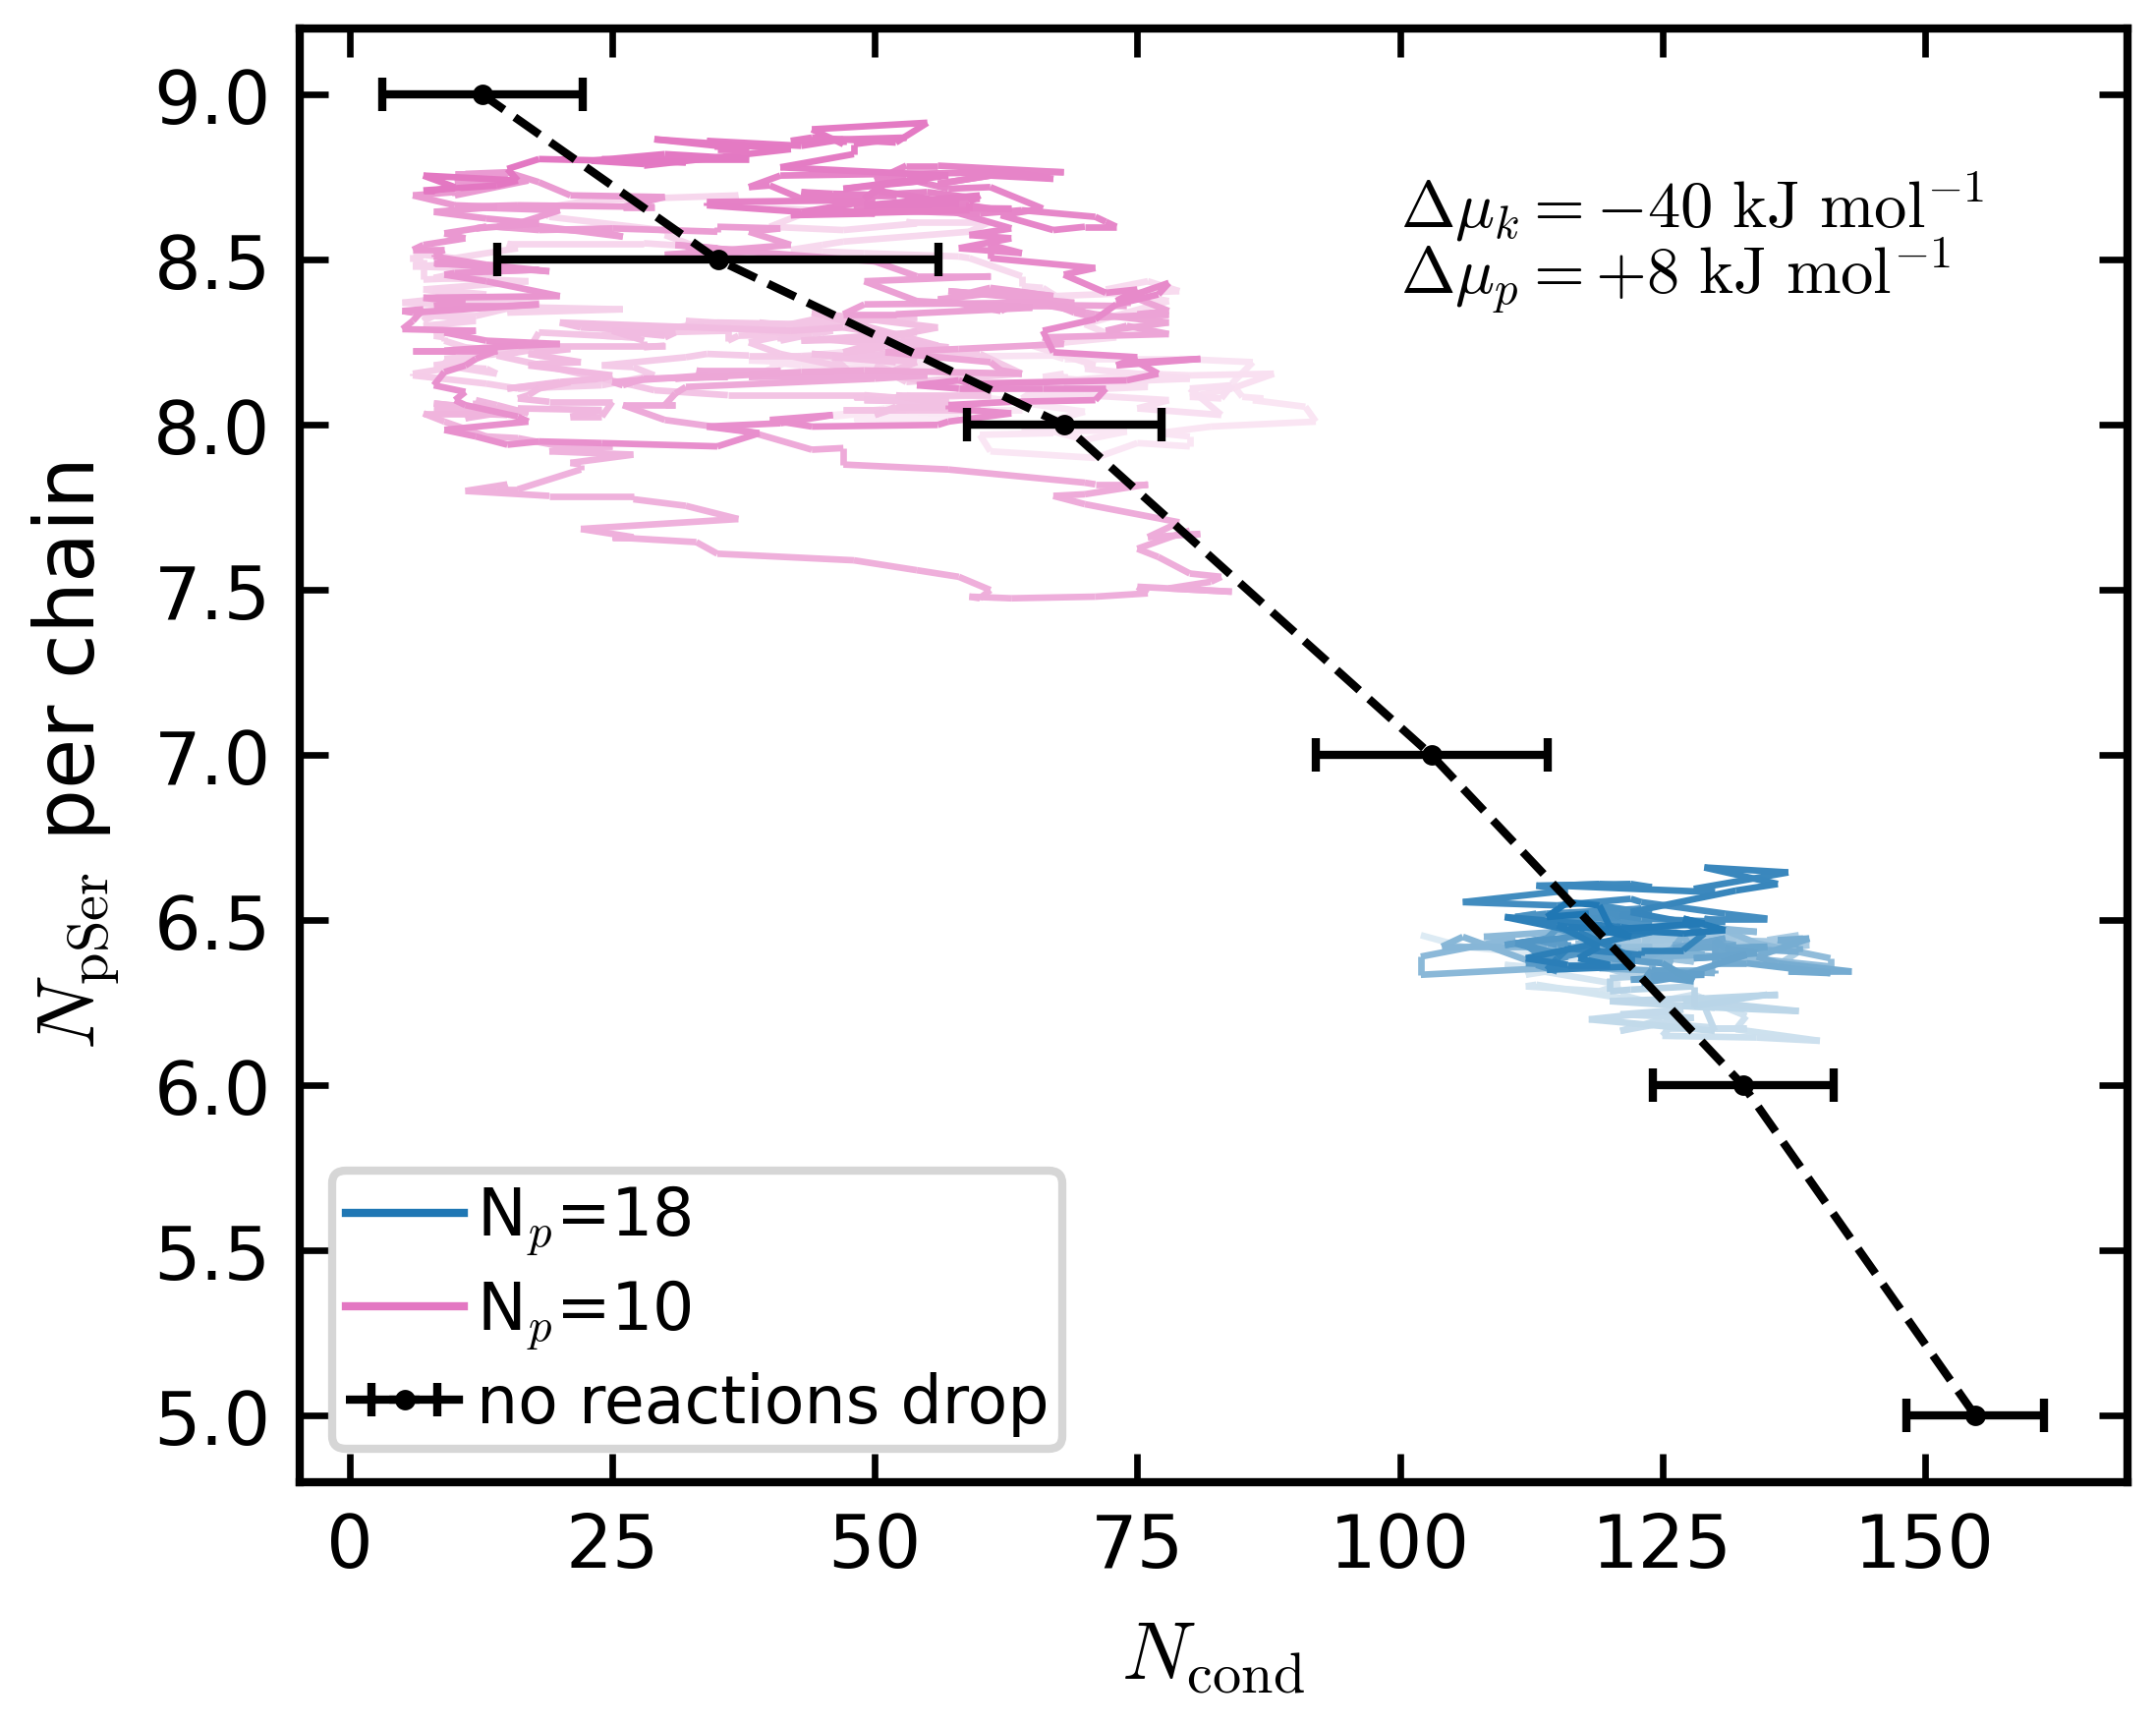

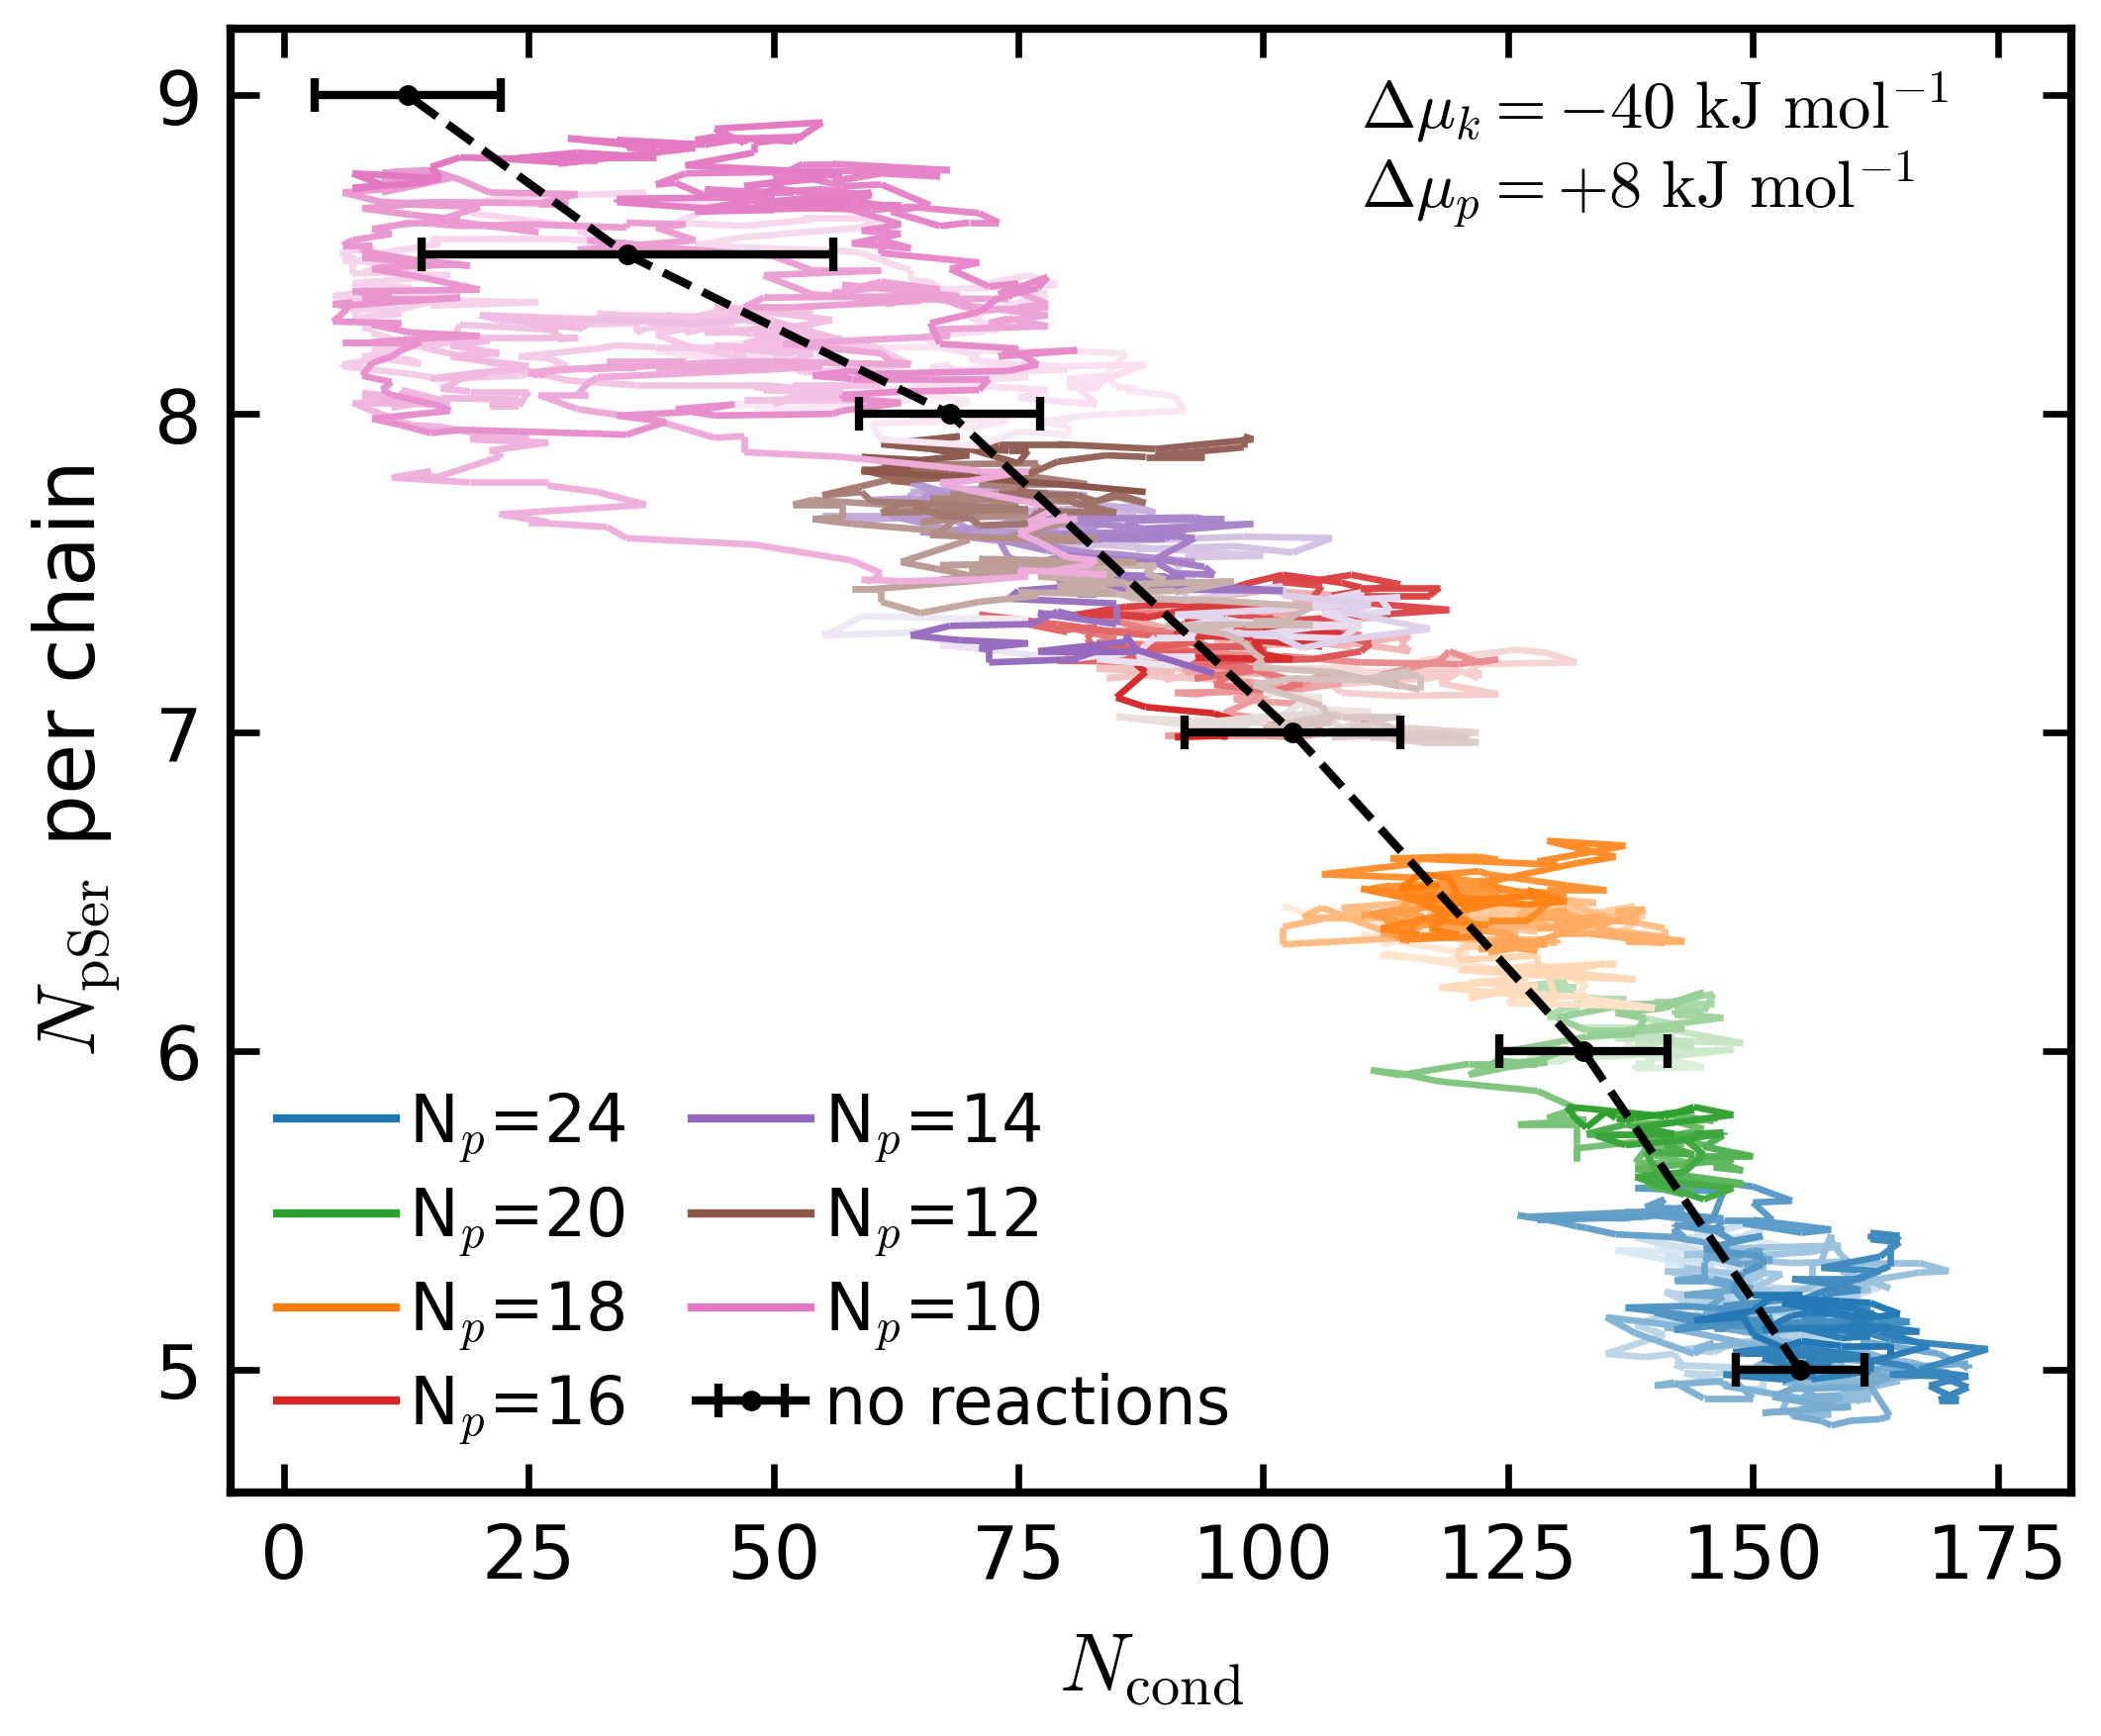

In [8]:
fig, ax = plt.subplots(figsize=(4, 3.2))
plot_lc(ax, '2_18', 'tab:blue', label='N$_p$=18', plot_mean=False)
plot_lc(ax, '2_10', 'tab:pink', label='N$_p$=10', plot_mean=False, therm=800)
ax.errorbar(cs_eq, np_eq, xerr=dcs_eq, capsize=2, fmt='.--k', label='no reactions drop')
driving_text(ax, 100, 8.6, '-40', '+8', dy=0.2)
finish_lc(ax, 'limit_cycles_drop_cond_size_10-18-PP3')

fig, ax = plt.subplots(figsize=(4, 3.2))
for label, color, therm in [('2_24', 'tab:blue', 0), ('2_20', 'tab:green', 200), ('2_18', 'tab:orange', 0), ('2_16', 'tab:red', 0),
                            ('2_14', 'tab:purple', 0), ('2_12', 'tab:brown', 1000), ('2_10', 'tab:pink', 800)]:
    plot_lc(ax, label, color, label=f'N$_p$={label.split("_")[1]}', plot_mean=False, therm=therm)
ax.errorbar(cs_eq, np_eq, xerr=dcs_eq, capsize=2, fmt='.--k', label='no reactions')
driving_text(ax, 110, 8.9, '-40', '+8')
finish_lc(ax, 'limit_cycles_drop_cond_size_2ck1d', loc='lower left', framealpha=0, ncols=2)

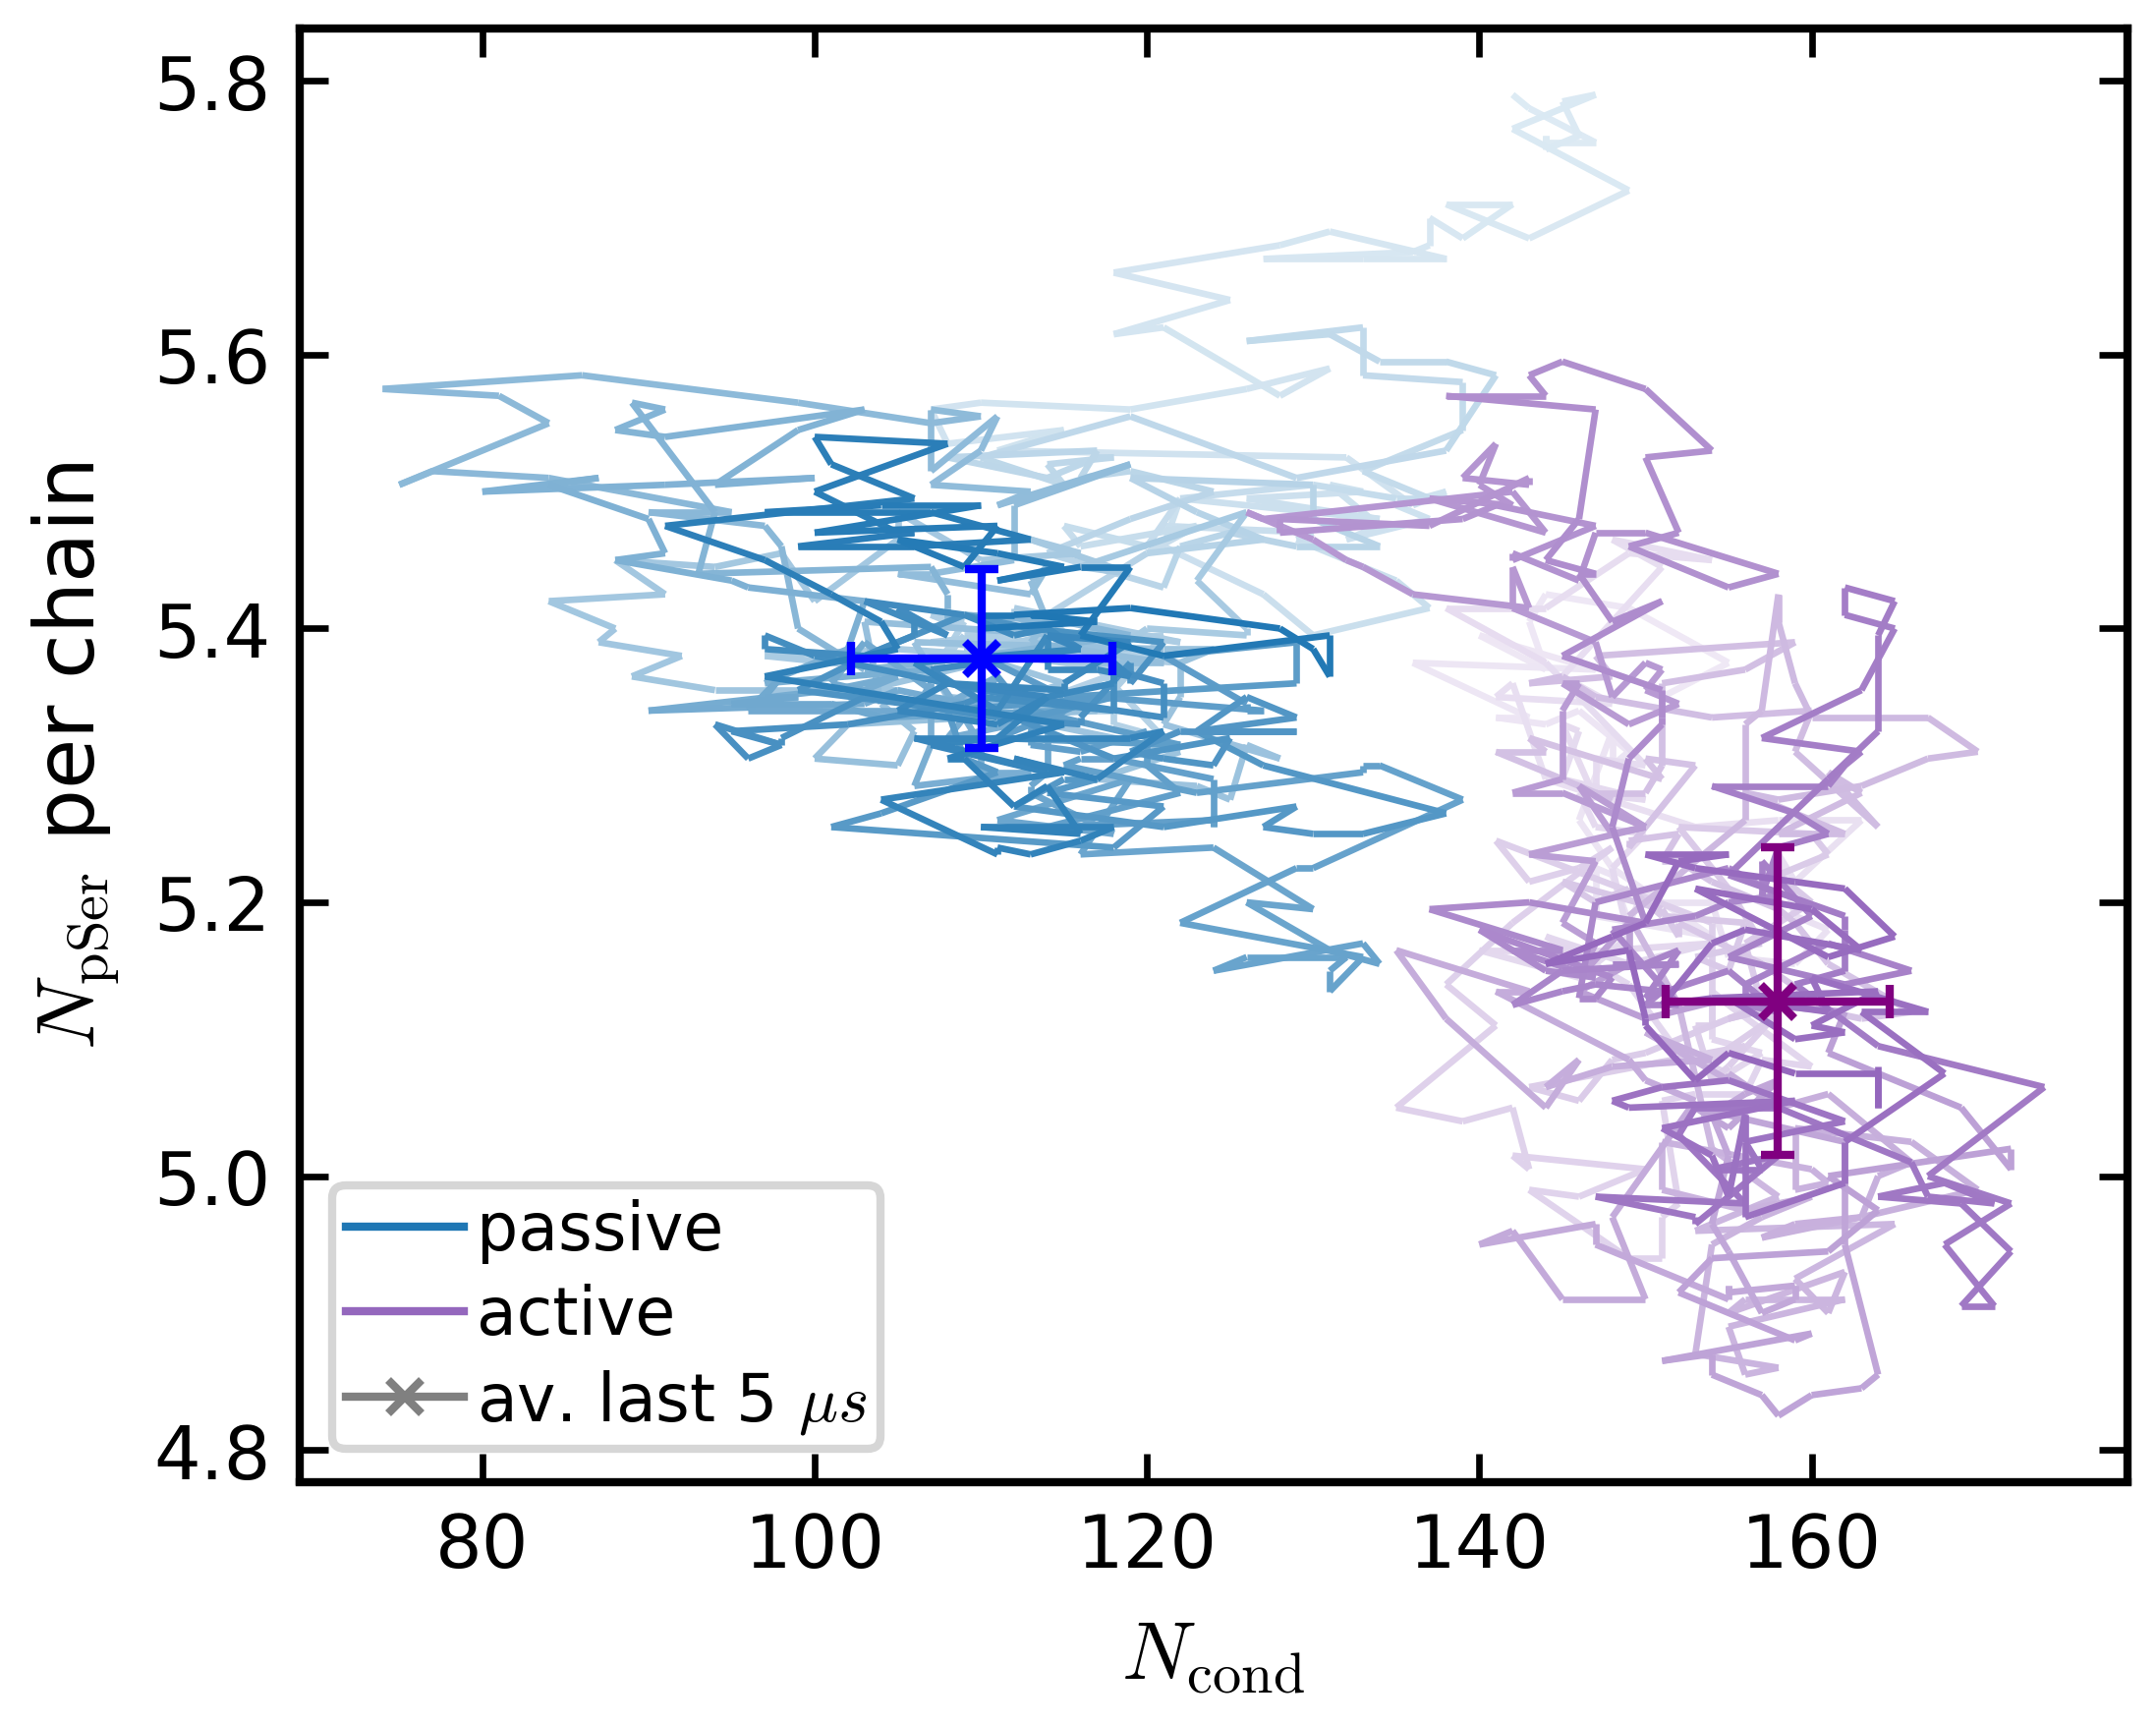

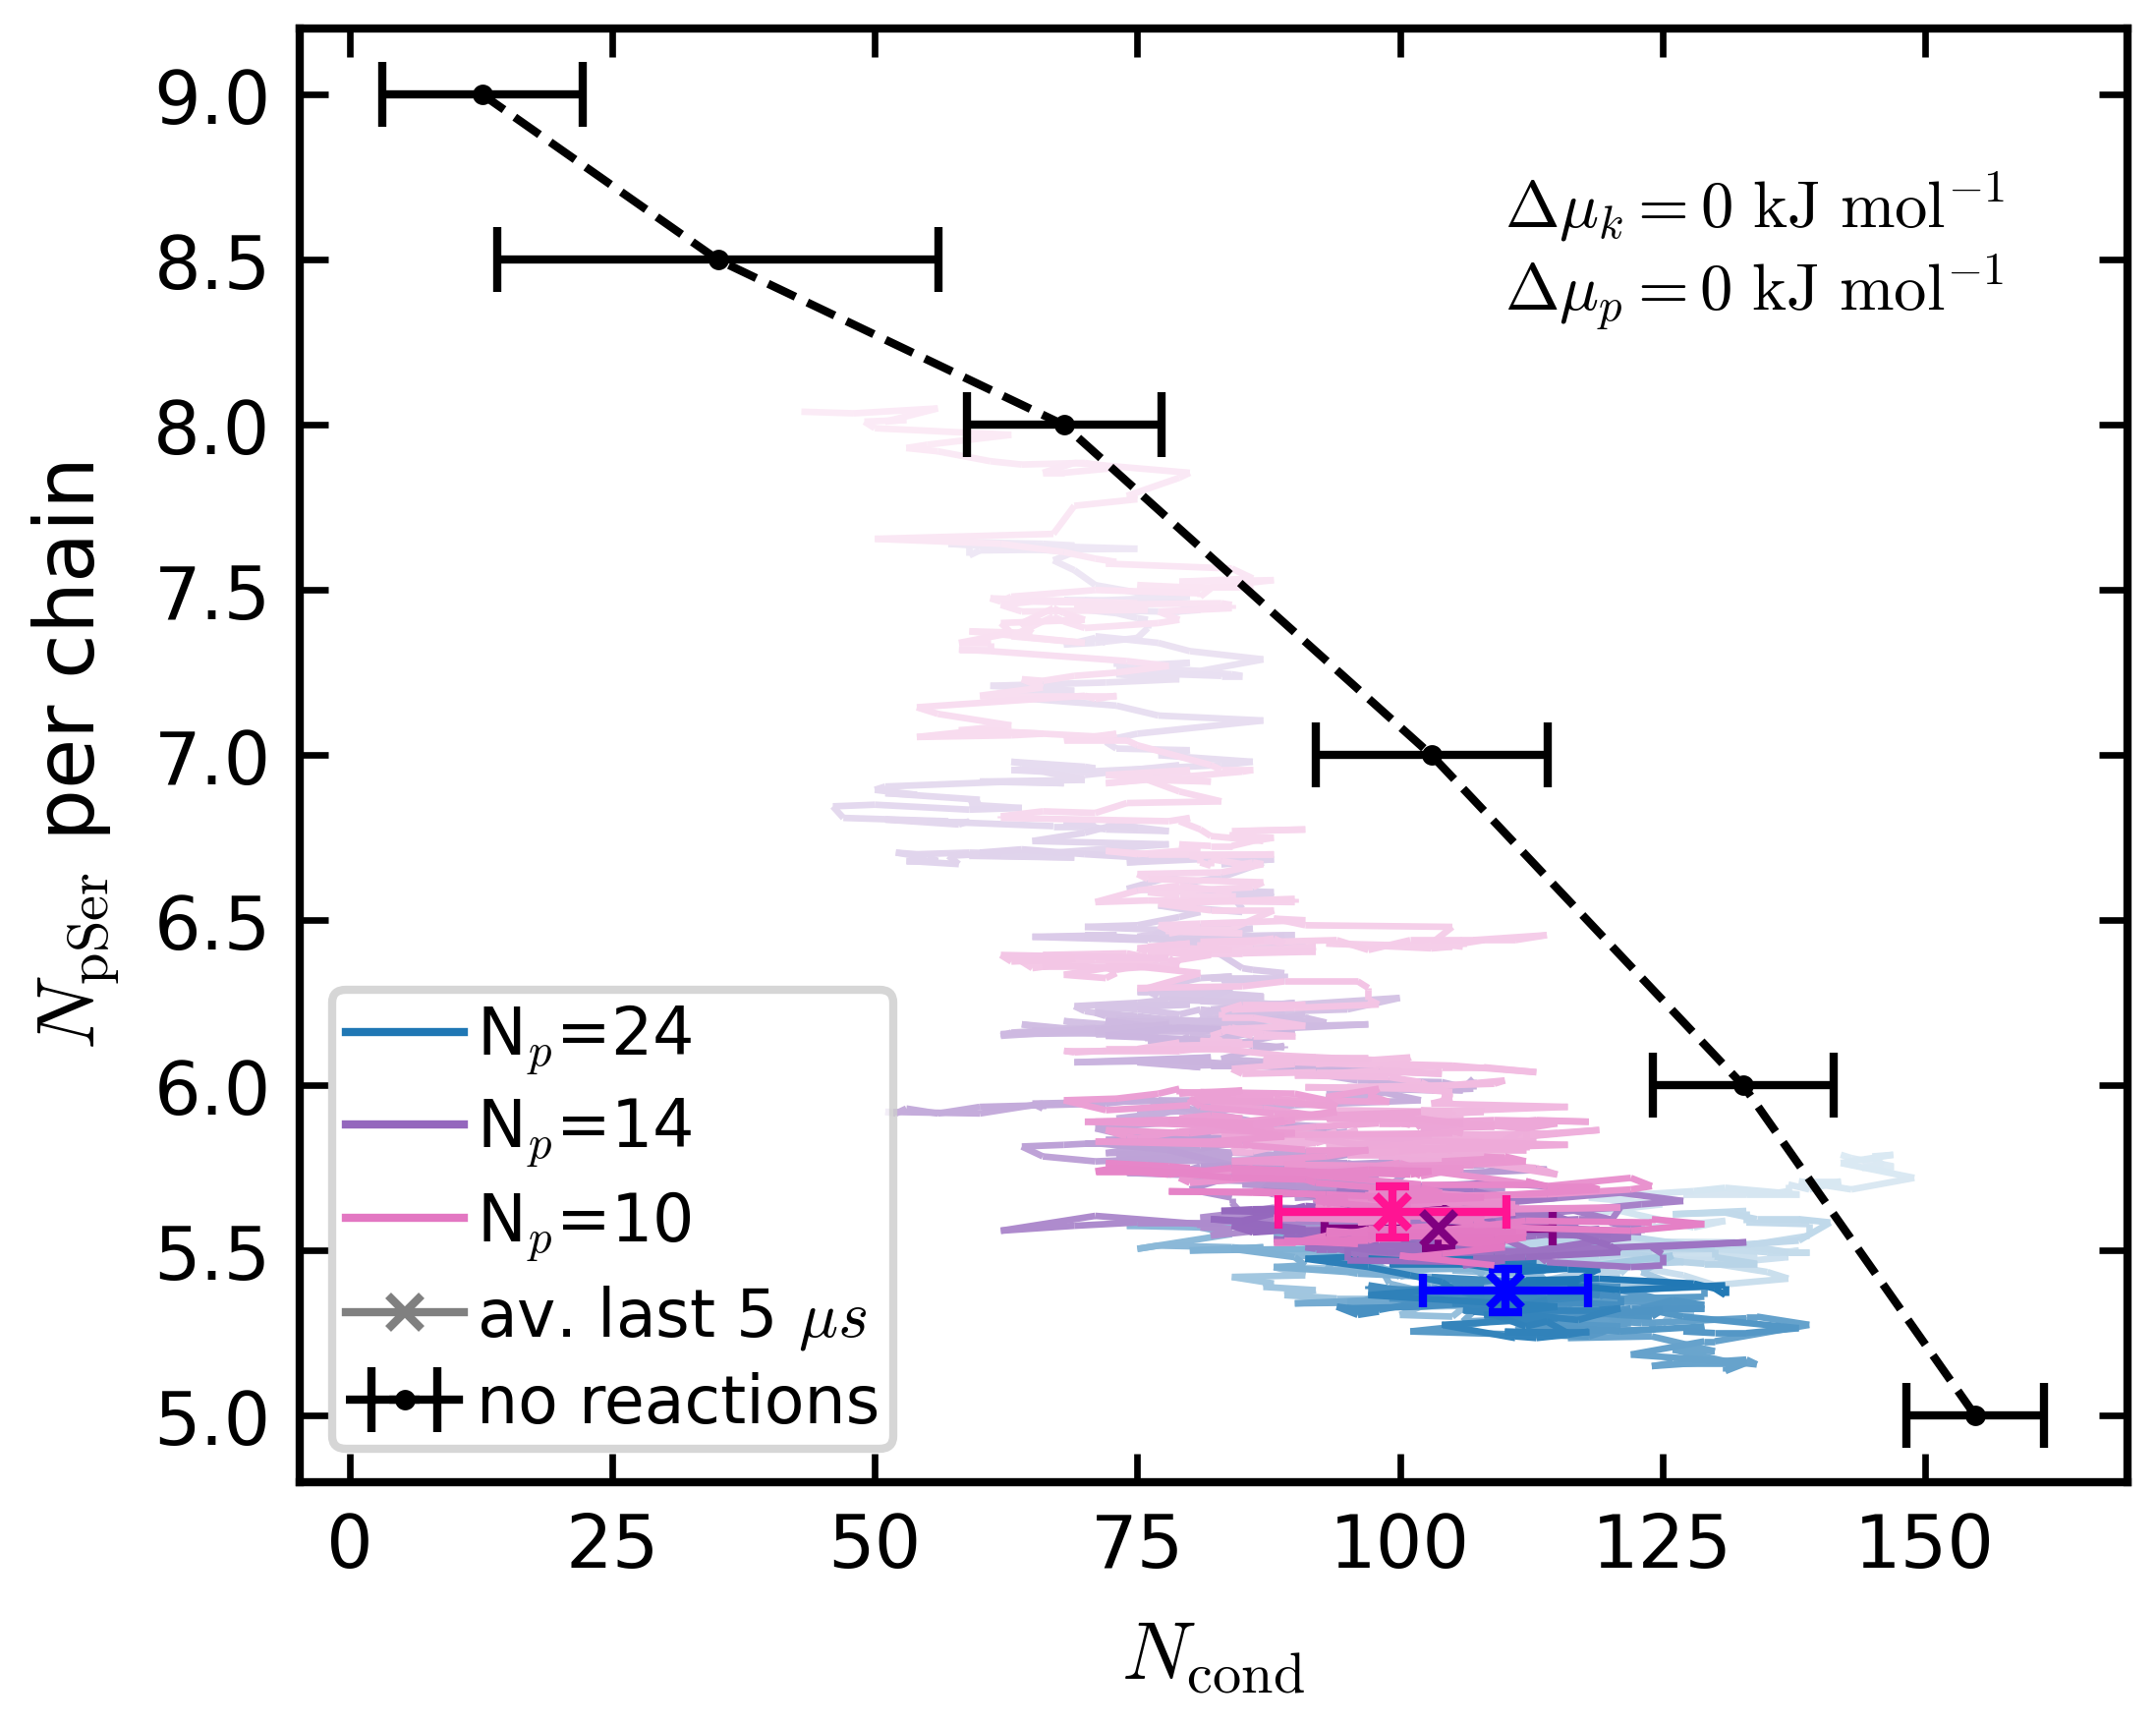

In [10]:
def last_average(ax, run, color, th=125):
    '''Mean +- std over the last `th` rows (last 5 us).'''
    _, cs, n_pser = lc[run]
    ax.errorbar(np.mean(cs[-th:]), np.mean(n_pser[-th:]) / 200, np.std(n_pser[-th:]) / 200, xerr=np.std(cs[-th:]),
                color=color, capsize=2, marker='x', ms=4)


fig, ax = plt.subplots(figsize=(4, 3.2))
plot_lc(ax, '2_24_dmu0', 'tab:blue', label='passive', plot_mean=False)
plot_lc(ax, '2_24', 'tab:purple', label='active', plot_mean=False)
last_average(ax, '2_24_dmu0', 'blue')
last_average(ax, '2_24', 'purple')
ax.errorbar([], [], capsize=2, color='grey', marker='x', ms=4, label=r'av. last 5 $\mu s$')
finish_lc(ax, 'limit_cycles_drop_cond_size_npser_active_vs_passive', loc='lower left')

fig, ax = plt.subplots(figsize=(4, 3.2))
for label, color, mean_color in [('2_24_dmu0', 'tab:blue', 'blue'), ('2_14_dmu0', 'tab:purple', 'purple'), ('2_10_dmu0', 'tab:pink', 'deeppink')]:
    plot_lc(ax, label, color, label=f'N$_p$={label.split("_")[1]}', plot_mean=False)
    last_average(ax, label, mean_color)
ax.errorbar([], [], capsize=2, color='grey', marker='x', ms=4, label=r'av. last 5 $\mu s$')
ax.errorbar(cs_eq, np_eq, xerr=dcs_eq, capsize=4, fmt='.--k', label='no reactions')
driving_text(ax, 110, 8.6, '0', '0')
finish_lc(ax, 'limit_cycles_drop_cond_size_nPP3_dmu0')

# 6. CK1δ in the condensate
Number of CK1δ in the largest cluster together with the cluster size, for one replica of each system in `CK1D_RUNS`
($N_k$ = 3, $N_p$ = 15 and $N_k$ = 2, $N_p$ = 10).

Clusters as in `hpa.cluster.chains_in_condensate` (freud, all beads, cutoff 1 nm): the condensate is the cluster with
the most TDP-43 beads, $N_{\mathrm{cond}}$ = its TDP-43 beads / 154 and CK1δ in the condensate = its CK1δ beads / 292
(a copy only partly in the cluster counts with the fraction of its beads). Same frames as the size files (every 20 dump frames).
The results are saved in the analysis folders (`sim{ss}_ck1d_in_cond_*.dat`) and reloaded; set `RECOMPUTE = True` to redo them.

In [ ]:
import freud


def enzyme_in_condensate(dump_files, enz_beads, enz_length, stride=20, cutoff=1.0, n_sub=N_PART):
    '''Chains in the largest cluster and enzyme copies in it, every `stride` frames of consecutive dump files.

    enz_beads: (first, last + 1) bead index of the enzyme; enz_length: beads per enzyme copy.
    Returns times [MD steps, frame index * DT_SNAP as in the size files], chains, enzyme copies.
    '''
    e0, e1 = enz_beads
    cl = freud.cluster.Cluster()
    times, chains, enzymes = [], [], []
    offset = 0
    for dump in dump_files:
        with gsd.hoomd.open(dump, 'rb') as traj:
            frames = np.arange(0, len(traj), stride)
            for i in tqdm(frames, desc=Path(dump).name):
                frame = traj[int(i)]
                cl.compute((freud.box.Box.from_box(frame.configuration.box), frame.particles.position),
                           neighbors={'r_max': cutoff})
                idx = cl.cluster_idx
                condensate = np.argmax(np.bincount(idx[:n_sub]))
                chains.append(np.sum(idx[:n_sub] == condensate) / CHAIN_LENGTH)
                enzymes.append(np.sum(idx[e0:e1] == condensate) / enz_length)
            times.append(frames + offset)
            offset += len(traj)
    return np.concatenate(times) * DT_SNAP, np.array(chains), np.array(enzymes)


# (N_k, N_p): (replica, consecutive dump files)
CK1D_RUNS = {(3, 15): (3, ('dump.gsd', '20us_dump.gsd')),
             (2, 10): (3, ('dump.gsd', '20us_dump.gsd', '40us_dump.gsd'))}
sim_type = 'ness'
LEN_CK1D = 292
RECOMPUTE = False


def ck1d_file(n_k, n_p, ss):
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_ck1d_in_cond_{drop_name(sim_type, n_k, n_p)[4:]}.dat'


ck1d_runs = {}      # (N_k, N_p) -> (times, N_cond, CK1d in condensate)
for (n_k, n_p), (ss, dump_names) in CK1D_RUNS.items():
    fn = ck1d_file(n_k, n_p, ss)
    if RECOMPUTE or not Path(fn).exists():
        dumps = [sim_prefix(sim_type, n_k, n_p, ss) + f'_fr01_{d}' for d in dump_names]
        ck1d_beads = (N_PART, N_PART + n_k * LEN_CK1D)      # CK1d copies follow the TDP-43 chains, then calcineurin
        t_ck, cs_ck, n_ck1d = enzyme_in_condensate(dumps, ck1d_beads, LEN_CK1D)
        np.savetxt(fn, np.column_stack([t_ck, cs_ck, n_ck1d]), header='time cond_size n_ck1d_in_cond')
    t_ck, cs_ck, n_ck1d = ck1d_runs[(n_k, n_p)] = np.loadtxt(fn, unpack=True)

    # check against the size file of this replica (same frames, same cluster definition)
    # (on 22/10/2026 only 0-20 us matched for 3/15 replica 3; its size file was recomputed from the current dumps
    #  on 27/10/2026 and now matches in every frame)
    t_sz, cs_sz, _ = read_chains_in_condensate(path_drop_fr_an, N_CHAINS, n_k, n_p, sim_type, ss)
    n = min(len(t_ck), len(t_sz))
    same = np.abs(cs_ck[:n] - cs_sz[:n]) < 0.01
    print(f'N_k={n_k}, N_p={n_p}, replica {ss}: N_cond equal to the size file in {same.sum()} of {n} frames' +
          ('' if same.all() else f' (first difference at t = {t_ck[np.argmin(same)] / 1e8:.1f} x 1e8 steps)'))
    print(f'    CK1d in the condensate: mean {n_ck1d.mean():.2f} of {n_k}, '
          f'all {n_k} in it {np.mean(n_ck1d > n_k - 0.5):.0%} of the time, none {np.mean(n_ck1d < 0.5):.0%}')

## Minimum distance of each CK1δ from the condensate
Same runs and frames as above. For every CK1δ copy: minimum distance (PBC) between any of its beads and the TDP-43 beads
of the largest cluster. About 0.5 nm when the copy is in contact with the condensate.
Saved as `sim{ss}_ck1d_dist_cond_*.dat` (columns: time, N_cond, one distance per CK1δ) and reloaded; `RECOMPUTE` as above.

In [41]:
def enzyme_distance_from_condensate(dump_files, enz_beads, enz_length, stride=20, cutoff=1.0, n_sub=N_PART):
    '''Chains in the largest cluster and minimum distance of every enzyme copy from its TDP-43 beads,
    every `stride` frames of consecutive dump files (clusters as in enzyme_in_condensate).
    Returns times [MD steps], chains, distances (n_frames, n_copies) [nm].
    '''
    e0, e1 = enz_beads
    n_copies = (e1 - e0) // enz_length
    cl = freud.cluster.Cluster()
    times, chains, dists = [], [], []
    offset = 0
    for dump in dump_files:
        with gsd.hoomd.open(dump, 'rb') as traj:
            frames = np.arange(0, len(traj), stride)
            for i in tqdm(frames, desc=Path(dump).name):
                frame = traj[int(i)]
                box = freud.box.Box.from_box(frame.configuration.box)
                pos = frame.particles.position
                cl.compute((box, pos), neighbors={'r_max': cutoff})
                idx = cl.cluster_idx
                condensate = np.argmax(np.bincount(idx[:n_sub]))
                cond_pos = pos[:n_sub][idx[:n_sub] == condensate]
                chains.append(len(cond_pos) / CHAIN_LENGTH)
                # nearest condensate bead of every enzyme bead (PBC), then minimum over the beads of each copy
                nlist = freud.locality.AABBQuery(box, cond_pos).query(pos[e0:e1], {'num_neighbors': 1}).toNeighborList()
                d_bead = np.full(e1 - e0, np.inf)
                np.minimum.at(d_bead, nlist.query_point_indices, nlist.distances)
                dists.append(d_bead.reshape(n_copies, enz_length).min(axis=1))
            times.append(frames + offset)
            offset += len(traj)
    return np.concatenate(times) * DT_SNAP, np.array(chains), np.array(dists)


def ck1d_dist_file(n_k, n_p, ss):
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_ck1d_dist_cond_{drop_name(sim_type, n_k, n_p)[4:]}.dat'


ck1d_dist = {}      # (N_k, N_p) -> (times, N_cond, distances (n_frames, N_k))
for (n_k, n_p), (ss, dump_names) in CK1D_RUNS.items():
    fn = ck1d_dist_file(n_k, n_p, ss)
    if RECOMPUTE or not Path(fn).exists():
        dumps = [sim_prefix(sim_type, n_k, n_p, ss) + f'_fr01_{d}' for d in dump_names]
        t_d, cs_d, d_ck = enzyme_distance_from_condensate(dumps, (N_PART, N_PART + n_k * LEN_CK1D), LEN_CK1D)
        np.savetxt(fn, np.column_stack([t_d, cs_d, d_ck]),
                   header='time cond_size ' + ' '.join(f'dmin_ck1d{j + 1}' for j in range(n_k)))
    data = np.loadtxt(fn)
    ck1d_dist[(n_k, n_p)] = (data[:, 0], data[:, 1], data[:, 2:])
    print(f'N_k={n_k}, N_p={n_p}, replica {ss}: median minimum distance per CK1d '
          f'{np.round(np.median(data[:, 2:], axis=0), 2)} nm; same N_cond as above: '
          f'{np.allclose(data[:, 1], ck1d_runs[(n_k, n_p)][1])}')

N_k=3, N_p=15, replica 3: median minimum distance per CK1d [0.51 0.52 0.51] nm; same N_cond as above: True
N_k=2, N_p=10, replica 3: median minimum distance per CK1d [0.51 0.52] nm; same N_cond as above: True


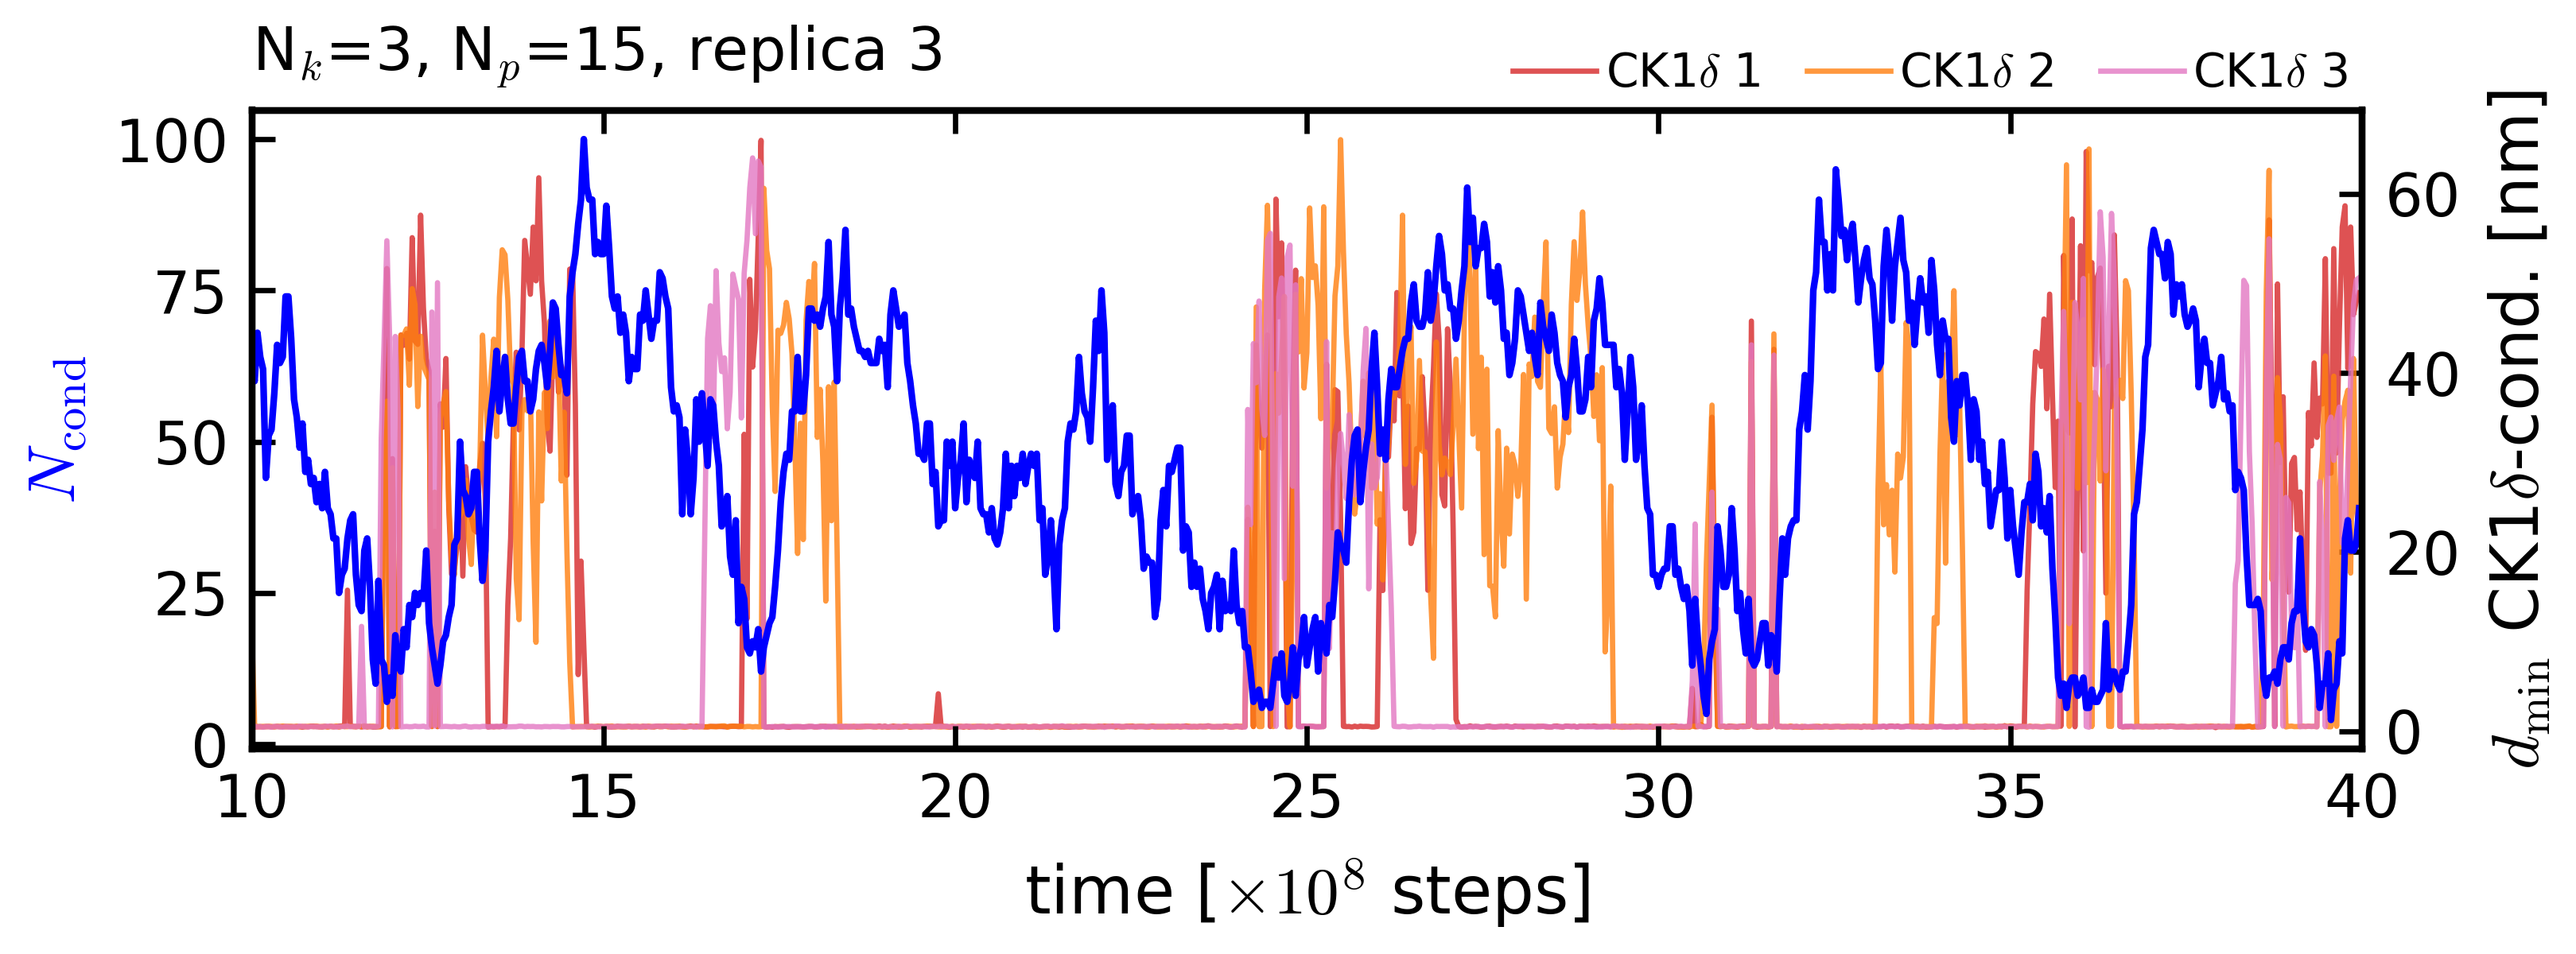

In [20]:
T_WINDOW = (10, 40)     # time window of the plot [1e8 steps], as in the plot above; None for the whole run

n_k = 3
n_p = 15
ss = 3

t_d, cs_d, d_ck = ck1d_dist[(n_k, n_p)]
fig, ax = plt.subplots(figsize=(5.6, 2.2))
ax.plot(t_d / 1e8, cs_d, 'b')
ax.set_ylabel(r'$N_{\mathrm{cond}}$', color='b')
axr = ax.twinx()
axr.set_zorder(ax.get_zorder() - 1)
for j, color in zip(range(n_k), ('tab:red', 'tab:orange', 'tab:pink')):
    axr.plot(t_d / 1e8, d_ck[:, j], color=color, lw=0.8, alpha=0.8, label=f'CK1$\\delta$ {j + 1}')
axr.set_ylabel(r'$d_{\min}$ CK1$\delta$-cond. [nm]')
sel = ((t_d / 1e8 >= T_WINDOW[0]) & (t_d / 1e8 <= T_WINDOW[1])) if T_WINDOW else slice(None)
axr.set_ylim(-2, 1.05 * d_ck[sel].max())
axr.legend(frameon=False, fontsize=7, ncol=n_k, loc='lower right', bbox_to_anchor=(1.0, 1.0), borderaxespad=0.1)
for a in (ax, axr):
    a.patch.set_visible(False)
ax.set_xlabel(r'time [$\times 10^8$ steps]')
ax.set_xlim(T_WINDOW if T_WINDOW else (0, t_d[-1] / 1e8))
ax.set_title(f'N$_k$={n_k}, N$_p$={n_p}, replica {ss}', loc='left', fontsize=9)
plt.tight_layout()
savefig(path_drop_fr_pl + f'{drop_name(sim_type, n_k, n_p)}/sim{ss}_cluster_size_ck1d_distance_200-tdp-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01', dpi=600)
plt.show()